# Flood Extent Mapping from Sentinel-1 SAR: Multi-Temporal Attention U-Net
Dataset: Kuro Siwo (training metadata for all 5 shards already audited: 25,707 patches, 25 events).
Fixed choices: input = `sec1_vv, sec1_vh, sec2_vv, sec2_vh, flood_vv, flood_vh`; target = `mask == 2`; `valid_mask` used for loss/metrics; SAR linear -> dB.

## 1. Setup

In [51]:
import gc, json, random, shutil, tarfile
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, torch
from huggingface_hub import HfApi, hf_hub_download

REPO = "orion-ai-lab/Kuro-Siwo-Webdataset"
SEED = 42
ROOT = Path("/kaggle/working/flood_mapping_project")
DATA = ROOT / "data"
TAR_DIR = DATA / "kuro_siwo"
for p in [DATA, TAR_DIR, ROOT / "checkpoints", ROOT / "results", ROOT / "figures"]:
    p.mkdir(parents=True, exist_ok=True)

SAR_FIELDS = ["sec1_vv", "sec1_vh", "sec2_vv", "sec2_vh", "flood_vv", "flood_vh"]

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| free disk (GB):", round(shutil.disk_usage("/kaggle/working").free / 1e9, 1))

Device: cuda | free disk (GB): 14.7


## 2. Helpers

In [52]:
def download_shard(split, i):
    name = f"{split}/shard-{i:05d}.tar"
    size = next(f.size for f in HfApi().list_repo_tree(REPO, path_in_repo=split, repo_type="dataset") if f.path == name)
    assert shutil.disk_usage("/kaggle/working").free > size + 1e9, "not enough disk"
    return Path(hf_hub_download(REPO, name, repo_type="dataset", local_dir=str(TAR_DIR)))

def extract_metadata(tar_path, shard):
    """Stream a shard and keep all scalar fields of each info.json (incl. grid_id) + source dates."""
    rows = []
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if m.isfile() and m.name.endswith(".info.json"):
                info = json.loads(tar.extractfile(m).read())
                r = {"sample_id": Path(m.name).name.split(".")[0], "shard": shard}
                r.update({k: v for k, v in info.items() if isinstance(v, (int, float, str, bool, type(None)))})
                s = info.get("sources", {})
                r["sl1_date"], r["sl2_date"], r["post_date"] = (s.get(k, {}).get("source_date") for k in ("SL1", "SL2", "MS1"))
                rows.append(r)
    return pd.DataFrame(rows)

## 3. Done: training metadata audit

In [53]:
df = pd.read_csv(DATA / "inspected_training_metadata.csv")
assert len(df) == 25707 and df["actid"].nunique() == 25

events = (df.groupby("actid")
            .agg(patches=("sample_id", "count"), flood_date=("flood_date", "first"),
                 mean_flood=("pflood", "mean"), zero_flood=("pflood", lambda x: int((x == 0).sum())))
            .sort_values("patches", ascending=False))
events["share_%"] = (events["patches"] / len(df) * 100).round(1)
display(events.round(2))

,patches,flood_date,mean_flood,zero_flood,share_%
actid,,,,,
1111009,7556,2022-09-10 08:00:00,31.28,149,29.4
1111013,6008,2017-05-03 08:00:00,5.31,1662,23.4
1111004,4086,2017-08-28 08:00:00,7.88,53,15.9
1111007,2329,2019-09-17 08:00:00,11.77,809,9.1
1111011,1619,2020-11-12 08:00:00,12.97,273,6.3
555,684,2021-12-10 11:00:00,4.00,232,2.7
1111005,620,2020-01-25 08:00:00,32.81,34,2.4
502,445,2021-02-23 04:00:00,3.25,172,1.7
497,398,2021-02-01 12:00:00,6.57,192,1.5


## 4. Done: validation-split candidates
Split by event, never by patch. Prefer a multi-event validation set (A or B); single huge events (C, D) are noisy.

In [54]:
options = {"A": [1111007, 1111011], "B": [1111005, 1111006, 1111011], "C": [1111009], "D": [1111013]}
display(pd.DataFrame([{"option": k, "events": v,
                       "val_patches": (df.actid.isin(v)).sum(),
                       "val_%": round(df.actid.isin(v).mean() * 100, 1),
                       "mean_flood": round(df[df.actid.isin(v)].pflood.mean(), 1),
                       "zero_flood_%": round((df[df.actid.isin(v)].pflood == 0).mean() * 100, 1)}
                      for k, v in options.items()]))

,option,events,val_patches,val_%,mean_flood,zero_flood_%
0,A,"[1111007, 1111011]",3948,15.4,12.3,27.4
1,B,"[1111005, 1111006, 1111011]",2552,9.9,18.3,12.6
2,C,[1111009],7556,29.4,31.3,2.0
3,D,[1111013],6008,23.4,5.3,27.7


## 5. NEXT STEP: check whether different events cover the same ground
Your saved CSV has no `grid_id`. This cell re-reads the metadata of all 5 training shards (download, read, delete; about 10-20 min per large shard), then counts `grid_id` values shared between events.
Result decides whether you can claim generalization to unseen *places*, or only to unseen *events*.

In [55]:
parts = []
for i in range(5):
    p = download_shard("train_GRD", i)
    parts.append(extract_metadata(p, f"{i:05d}"))
    p.unlink(); gc.collect()
    print(f"shard {i} done")

df2 = pd.concat(parts, ignore_index=True)
df2.to_csv(DATA / "train_metadata_v2.csv", index=False)
print(df2.shape, list(df2.columns))

train_GRD/shard-00000.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00000.tar: downloading bytes:           |  0.00B            

shard 0 done


train_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00001.tar: downloading bytes:           |  0.00B            

shard 1 done


... (5 outputs left out)

shard 3 done


train_GRD/shard-00004.tar: reconstructing file:   0%|          |  0.00B / 3.11GB            

train_GRD/shard-00004.tar: downloading bytes:           |  0.00B            

shard 4 done
(25707, 18) ['sample_id', 'shard', 'grid_id', 'slavecov', 'mastercov', 'gvalid', 'pcovered', 'pwater', 'pflood', 'actid', 'flood_date', 'aoiid', 'revision', 'version', 'geom', 'sl1_date', 'sl2_date', 'post_date']


In [56]:
n_events_per_grid = df2.groupby("grid_id")["actid"].nunique()
shared = n_events_per_grid[n_events_per_grid > 1]
print("unique grid_id:", df2.grid_id.nunique())
print("grid_id shared by >1 event:", len(shared))
print("patches in shared grids: %.1f%%" % (df2.grid_id.isin(shared.index).mean() * 100))

unique grid_id: 25707
grid_id shared by >1 event: 0
patches in shared grids: 0.0%


### Result of the grid check
`grid_id` is unique for every patch (25,707 of 25,707), so it identifies a *patch*, not a *place*. It cannot show whether events overlap geographically.
**Consequence:** claim generalization to **unseen flood events** only, not unseen locations. The next cell lists the other metadata fields in case one of them encodes location.

In [57]:
print(df2.columns.tolist())
print(df2.nunique().sort_values().to_string())

['sample_id', 'shard', 'grid_id', 'slavecov', 'mastercov', 'gvalid', 'pcovered', 'pwater', 'pflood', 'actid', 'flood_date', 'aoiid', 'revision', 'version', 'geom', 'sl1_date', 'sl2_date', 'post_date']
slavecov          1
mastercov         1
gvalid            1
revision          1
version           2
shard             5
aoiid             9
actid            25
flood_date       25
sl1_date         26
post_date        26
sl2_date         26
pcovered        783
sample_id      6000
pwater         6643
pflood        12101
geom          25707
grid_id       25707


## 6. Final split (event-wise) and per-event cap
- **Validation:** events 1111007, 1111011, 555 (three events, different flood prevalence).
- **Training:** all other training events.
- **Test:** official `test_GRD` shards (Section 8). Never used for model selection.
- **Cap:** at most `CAP` random patches per event, so 1111009 / 1111013 / 1111004 do not dominate.

In [58]:
VAL_EVENTS = [1111007, 1111011, 555]
CAP = 1500

df2 = pd.read_csv(DATA / "train_metadata_v2.csv", dtype={"sample_id": str, "shard": str})
df2["split"] = np.where(df2["actid"].isin(VAL_EVENTS), "val", "train")
df2["gap_days"] = (pd.to_datetime(df2["post_date"], errors="coerce", utc=True)
                   - pd.to_datetime(df2["sl1_date"], errors="coerce", utc=True)).dt.days

rng = np.random.default_rng(SEED)
keep = []
for (split, event), g in df2.groupby(["split", "actid"]):
    idx = g.index.to_numpy()
    if len(idx) > CAP:
        idx = rng.choice(idx, CAP, replace=False)
    keep.append(idx)

manifest = df2.loc[np.sort(np.concatenate(keep))].sort_values(["shard", "sample_id"]).reset_index(drop=True)
manifest["row"] = manifest.groupby("split").cumcount()      # row index inside X_<split>.npy / Y_<split>.npy

assert not set(manifest[manifest.split == "train"].actid) & set(VAL_EVENTS)
PROC = DATA / "processed"; PROC.mkdir(exist_ok=True)
manifest.to_csv(PROC / "manifest_trainval.csv", index=False)

summary = manifest.groupby("split").agg(patches=("row", "size"), events=("actid", "nunique"),
                                        mean_flood=("pflood", "mean"),
                                        zero_flood_pct=("pflood", lambda x: (x == 0).mean() * 100))
summary["approx_GB"] = summary["patches"] * (6 * 224 * 224 + 224 * 224) / 1e9
display(summary.round(2))
print("Median pre->post gap (days):", manifest["gap_days"].median(), "| max:", manifest["gap_days"].max())

,patches,events,mean_flood,zero_flood_pct,approx_GB
split,,,,,
train,7925,22,15.18,14.23,2.78
val,3684,3,10.77,27.33,1.29


Median pre->post gap (days): 36.0 | max: 672


## 7. Preprocessing pass (train + validation)
One streaming pass per training shard: download, convert, write, delete.
- SAR: linear to dB, clipped to [-30, +5] dB, stored as **uint8** (about 0.14 dB per level).
- Label: original mask (0, 1, 2) with **255 = invalid pixel** (`valid_mask == 0`). Flood target = `label == 2`; ignore `label == 255`.
- Arrays: `X_<split>.npy` shape (N, 6, 224, 224), `Y_<split>.npy` shape (N, 224, 224). Resumable: finished shards are recorded in `done.json`.

In [59]:
import io

DB_MIN, DB_MAX, IGNORE = -30.0, 5.0, 255
SCALE = (DB_MAX - DB_MIN) / 255.0
NEED = set(SAR_FIELDS) | {"mask", "valid_mask"}

def encode_sar(x):                      # (6,H,W) linear -> uint8
    db = 10.0 * np.log10(np.clip(np.nan_to_num(x, nan=1e-4), 1e-4, None))
    return np.rint(np.clip((db - DB_MIN) / (DB_MAX - DB_MIN), 0, 1) * 255).astype(np.uint8)

def encode_label(mask, valid):          # -> uint8, 255 where invalid
    lab = mask.astype(np.uint8)
    lab[valid <= 0] = IGNORE
    return lab

def open_arrays(split, n):
    out = []
    for name, shape in [("X", (n, 6, 224, 224)), ("Y", (n, 224, 224))]:
        f = PROC / f"{name}_{split}.npy"
        out.append(np.load(f, mmap_mode="r+") if f.exists()
                   else np.lib.format.open_memmap(f, mode="w+", dtype=np.uint8, shape=shape))
    return out

def preprocess_shard(tar_path, wanted, X, Y):
    """wanted: {sample_id: (split, row)}; X, Y: dicts split -> memmap. Streams the tar once."""
    buf, written = {}, 0
    with tarfile.open(tar_path, "r:") as tar:
        for m in tar:
            if not m.isfile():
                continue
            key, _, field = Path(m.name).name.partition(".")
            if key not in wanted or not field.endswith(".npy") or field[:-4] not in NEED:
                continue
            buf.setdefault(key, {})[field[:-4]] = np.load(io.BytesIO(tar.extractfile(m).read()),
                                                           allow_pickle=False).squeeze()
            if len(buf[key]) == len(NEED):
                s = buf.pop(key)
                split, row = wanted[key]
                X[split][row] = encode_sar(np.stack([s[f] for f in SAR_FIELDS]))
                Y[split][row] = encode_label(s["mask"], s["valid_mask"])
                written += 1
    assert written == len(wanted) and not buf, f"wrote {written}/{len(wanted)}; incomplete: {len(buf)}"
    for a in list(X.values()) + list(Y.values()):
        a.flush()
    return written

DONE = PROC / "done.json"
done = set(json.loads(DONE.read_text())) if DONE.exists() else set()
def mark_done(k):
    done.add(k); DONE.write_text(json.dumps(sorted(done)))

In [60]:
n_split = manifest.groupby("split").size().to_dict()
X, Y = {}, {}
for split, n in n_split.items():
    X[split], Y[split] = open_arrays(split, n)

for i in range(5):
    key = f"train_{i:05d}"
    if key in done:
        print(key, "already done"); continue
    sub = manifest[manifest["shard"] == f"{i:05d}"]
    wanted = {r.sample_id: (r.split, r.row) for r in sub.itertuples()}
    p = download_shard("train_GRD", i)
    n = preprocess_shard(p, wanted, X, Y)
    p.unlink(); gc.collect(); mark_done(key)
    print(f"{key}: wrote {n} patches | free disk {shutil.disk_usage('/kaggle/working').free / 1e9:.1f} GB")

train_00000 already done
train_00001 already done
train_00002 already done
train_00003 already done
train_00004 already done


### Train-only normalization statistics
Computed from the stored **training** arrays only (no extra download). Also reports how many pixels hit the clipping limits (0 or 255), to confirm the [-30, +5] dB range is adequate.

In [61]:
Xtr = np.load(PROC / "X_train.npy", mmap_mode="r")
Ytr = np.load(PROC / "Y_train.npy", mmap_mode="r")

s1 = np.zeros(6); s2 = np.zeros(6); lo = np.zeros(6); hi = np.zeros(6); n = 0
for a in range(0, len(Xtr), 64):
    q = np.asarray(Xtr[a:a + 64]); v = np.asarray(Ytr[a:a + 64]) != IGNORE
    qv = q.transpose(1, 0, 2, 3)[:, v].astype(np.float64)       # (6, n_valid)
    s1 += qv.sum(1); s2 += (qv ** 2).sum(1)
    lo += (qv == 0).sum(1); hi += (qv == 255).sum(1); n += qv.shape[1]

mean_q = s1 / n
std_q = np.sqrt(s2 / n - mean_q ** 2)
norm = {"channels": SAR_FIELDS, "db_min": DB_MIN, "db_max": DB_MAX,
        "mean_db": (mean_q * SCALE + DB_MIN).tolist(), "std_db": (std_q * SCALE).tolist()}
(PROC / "norm_stats.json").write_text(json.dumps(norm, indent=2))

display(pd.DataFrame({"mean_dB": norm["mean_db"], "std_dB": norm["std_db"],
                      "clipped_low_%": lo / n * 100, "clipped_high_%": hi / n * 100}, index=SAR_FIELDS).round(3))

,mean_dB,std_dB,clipped_low_%,clipped_high_%
sec1_vv,-10.962,3.521,0.011,0.115
sec1_vh,-18.035,4.164,1.212,0.004
sec2_vv,-11.134,3.555,0.011,0.114
sec2_vh,-18.082,4.226,1.302,0.004
flood_vv,-11.210,4.703,0.104,0.144
flood_vh,-17.872,5.040,3.205,0.005


### Sanity checks
Visual check of one stored sample, and a check that stored labels match the metadata (flood fraction vs `pflood`).

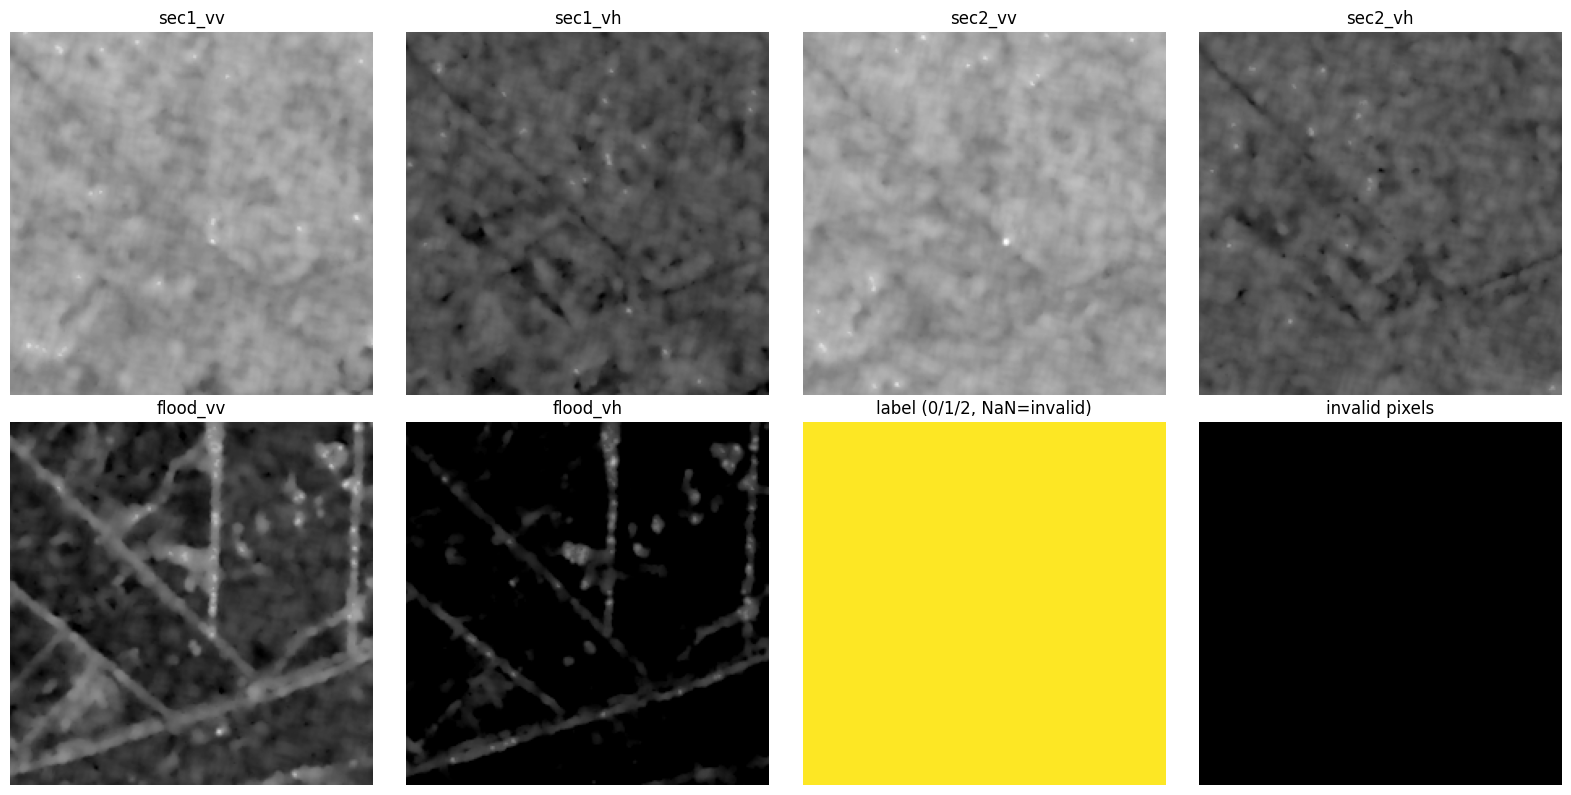

corr(stored flood %, metadata pflood): 1.0
X: (7925, 6, 224, 224) uint8 | Y: (7925, 224, 224) uint8


In [62]:
import matplotlib.pyplot as plt

k = int(np.argmax(manifest[manifest.split == "train"].pflood.to_numpy()))   # a flood-heavy patch
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for c in range(6):
    ax.flat[c].imshow(Xtr[k, c] * SCALE + DB_MIN, cmap="gray", vmin=-25, vmax=0)
    ax.flat[c].set_title(SAR_FIELDS[c]); ax.flat[c].axis("off")
lab = np.asarray(Ytr[k]).astype(float); lab[lab == IGNORE] = np.nan
ax.flat[6].imshow(lab, cmap="viridis", vmin=0, vmax=2); ax.flat[6].set_title("label (0/1/2, NaN=invalid)"); ax.flat[6].axis("off")
ax.flat[7].imshow(np.asarray(Ytr[k]) == IGNORE, cmap="gray"); ax.flat[7].set_title("invalid pixels"); ax.flat[7].axis("off")
plt.tight_layout(); plt.show()

tr = manifest[manifest.split == "train"]
frac = np.array([(np.asarray(Ytr[i]) == 2).mean() * 100 for i in range(len(Ytr))])
print("corr(stored flood %, metadata pflood):", round(np.corrcoef(frac, tr.pflood.to_numpy())[0, 1], 4))
print("X:", Xtr.shape, Xtr.dtype, "| Y:", Ytr.shape, Ytr.dtype)

## 8. Test set: official `test_GRD` shard(s)
Downloads a test shard, reads its metadata, converts **all** its patches with the same encoding (no cap, no normalization needed yet), and deletes it. Then checks whether its events are disjoint from training/validation events.
Start with one shard (about 10 GB download); add more indices to `TEST_SHARDS` later if you need more test data.

In [63]:
TEST_SHARDS = [0]

for i in TEST_SHARDS:
    split = f"test_{i:02d}"
    if split in done:
        print(split, "already done"); continue
    p = download_shard("test_GRD", i)
    meta = extract_metadata(p, f"{i:05d}")
    meta["split"] = split; meta["row"] = np.arange(len(meta))
    Xt, Yt = open_arrays(split, len(meta))
    wanted = {r.sample_id: (split, r.row) for r in meta.itertuples()}
    preprocess_shard(p, wanted, {split: Xt}, {split: Yt})
    meta.to_csv(PROC / f"manifest_{split}.csv", index=False)
    p.unlink(); gc.collect(); mark_done(split)
    print(f"{split}: {len(meta):,} patches, {meta.actid.nunique()} events")

test_events = set()
for f in PROC.glob("manifest_test_*.csv"):
    test_events |= set(pd.read_csv(f)["actid"].unique())
print("Test events:", sorted(test_events))
print("Overlap with train/val events:", sorted(test_events & set(df2.actid.unique())) or "none")

test_00 already done
Test events: [np.int64(118), np.int64(130), np.int64(147), np.int64(174), np.int64(205), np.int64(267), np.int64(273), np.int64(275), np.int64(277)]
Overlap with train/val events: none


### Test-set check (result)
Test shard 0: 6,000 patches, 9 events (118, 130, 147, 174, 205, 267, 273, 275, 277), **none** shared with training/validation. The official test split is event-disjoint, so it is our test set. It is used only for final reporting.

## 9. Dataset and DataLoader
Reads the stored uint8 arrays, converts back to dB, and standardizes with the training statistics (`normalize=True`). `normalize=False` returns raw dB (used by the change-detection baseline).
Each item: `x` (6,224,224) float32, `target` (224,224) float32 (flood = 1), `valid` (224,224) bool.
Augmentation (training only): random horizontal flip, vertical flip and 90-degree rotation, applied identically to image and label.

In [64]:
from torch.utils.data import Dataset, DataLoader

NORM = json.loads((PROC / "norm_stats.json").read_text())
MEAN = np.array(NORM["mean_db"], dtype=np.float32)[:, None, None]
STD  = np.array(NORM["std_db"],  dtype=np.float32)[:, None, None]

class FloodDataset(Dataset):
    def __init__(self, split, augment=False, normalize=True):
        self.split, self.augment, self.normalize = split, augment, normalize
        self.X = self.Y = None                                   # opened lazily (per worker)
        man = (pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
               if split in ("train", "val")
               else pd.read_csv(PROC / f"manifest_{split}.csv", dtype={"sample_id": str, "shard": str}))
        self.meta = man[man["split"] == split].sort_values("row").reset_index(drop=True)
        self.actid = self.meta["actid"].to_numpy()

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, i):
        if self.X is None:
            self.X = np.load(PROC / f"X_{self.split}.npy", mmap_mode="r")
            self.Y = np.load(PROC / f"Y_{self.split}.npy", mmap_mode="r")
        x = np.asarray(self.X[i]).astype(np.float32) * SCALE + DB_MIN          # dB
        if self.normalize:
            x = (x - MEAN) / STD
        lab = np.asarray(self.Y[i])
        target = (lab == 2).astype(np.float32)
        valid = lab != IGNORE
        if self.augment:
            if random.random() < 0.5: x, target, valid = x[:, :, ::-1], target[:, ::-1], valid[:, ::-1]
            if random.random() < 0.5: x, target, valid = x[:, ::-1], target[::-1], valid[::-1]
            k = random.randint(0, 3)
            if k: x, target, valid = np.rot90(x, k, (1, 2)), np.rot90(target, k), np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(target)),
                torch.from_numpy(np.ascontiguousarray(valid)))

def make_loader(split, batch_size=16, augment=False, normalize=True, shuffle=False, workers=2):
    return DataLoader(FloodDataset(split, augment, normalize), batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=True, drop_last=False,
                      persistent_workers=workers > 0)

ds = FloodDataset("train", augment=True)
x, t, v = ds[0]
print(len(ds), x.shape, x.dtype, t.shape, v.dtype, "| flood px:", int(t.sum()), "| invalid px:", int((~v).sum()))
print("per-channel mean/std of this sample (should be roughly 0 / 1):", x.mean((1, 2)).numpy().round(2), x.std((1, 2)).numpy().round(2))

7925 torch.Size([6, 224, 224]) torch.float32 torch.Size([224, 224]) torch.bool | flood px: 879 | invalid px: 0
per-channel mean/std of this sample (should be roughly 0 / 1): [-0.41 -0.6  -0.39 -0.66  0.17  0.3 ] [0.37 0.46 0.37 0.44 0.35 0.36]


## 10. Metrics
Pooled over **valid** pixels (flood = positive class): IoU, F1, precision, recall. Counts are accumulated across all patches (not averaged per patch), and also per event.

In [65]:
def metrics_from_counts(tp, fp, fn, tn):
    tp, fp, fn, tn = map(float, (tp, fp, fn, tn))
    return {"IoU": tp / max(tp + fp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1)}

def evaluate(predict_fn, loader, threshold=0.5):
    """predict_fn(x) -> flood probability (B,H,W). Returns (pooled metrics dict, per-event DataFrame)."""
    actid = loader.dataset.actid
    per_event, tot, i = {}, np.zeros(4), 0
    for x, t, v in loader:
        pred = predict_fn(x.to(DEVICE, non_blocking=True)).detach().cpu() > threshold
        t, v = t.bool(), v.bool()
        for j in range(len(x)):
            vj, pj, tj = v[j], pred[j], t[j]
            c = np.array([(pj & tj & vj).sum(), (pj & ~tj & vj).sum(), (~pj & tj & vj).sum(), (~pj & ~tj & vj).sum()], dtype=np.float64)
            per_event.setdefault(int(actid[i + j]), np.zeros(4))
            per_event[int(actid[i + j])] += c; tot += c
        i += len(x)
    rows = [{"actid": e, "patches": int((actid == e).sum()), **metrics_from_counts(*c)} for e, c in sorted(per_event.items())]
    return metrics_from_counts(*tot), pd.DataFrame(rows)

def show(name, pooled, per_event=None):
    print(f"{name}: " + " | ".join(f"{k} {v:.4f}" for k, v in pooled.items()))
    if per_event is not None:
        display(per_event.round(4))

## 11. Baseline 1: change detection (no learning)
Flood water lowers radar backscatter, so a simple rule is: flag a pixel as flood if the post-event dB is much lower than the pre-event dB.
Feature candidates (all in dB): `vv_change = post_VV - mean(pre_VV)`, `vh_change`, `vv_vh_change` (average of both), and `post_vv_only` (no pre-event information; shows what temporal information adds).
The single threshold is chosen on the **training** set (maximum IoU), then applied unchanged to validation and test.

In [66]:
def feature(name, x):
    """x: (B,6,H,W) raw dB tensor -> (B,H,W) feature; flood if feature < threshold."""
    s1v, s1h, s2v, s2h, fv, fh = (x[:, i] for i in range(6))
    if name == "vv_change":    return fv - (s1v + s2v) / 2
    if name == "vh_change":    return fh - (s1h + s2h) / 2
    if name == "vv_vh_change": return ((fv - (s1v + s2v) / 2) + (fh - (s1h + s2h) / 2)) / 2
    if name == "post_vv_only": return fv
    raise ValueError(name)

FEATURES = ["vv_change", "vh_change", "vv_vh_change", "post_vv_only"]
EDGES = np.arange(-60, 40.01, 0.1)

def fit_threshold(loader, name):
    pos, neg = np.zeros(len(EDGES) - 1), np.zeros(len(EDGES) - 1)
    for x, t, v in loader:
        f = feature(name, x).clamp(EDGES[0], EDGES[-1] - 1e-3)
        v, t = v.bool(), t.bool()
        pos += np.histogram(f[v & t].numpy(), EDGES)[0]
        neg += np.histogram(f[v & ~t].numpy(), EDGES)[0]
    tp, fp = np.cumsum(pos), np.cumsum(neg)               # predict flood if feature < upper bin edge
    fn = pos.sum() - tp
    iou = tp / np.maximum(tp + fp + fn, 1)
    b = int(np.argmax(iou))
    return float(EDGES[b + 1]), float(iou[b])

train_raw = make_loader("train", batch_size=32, normalize=False, workers=2)
thresholds = {}
for name in FEATURES:
    thr, iou = fit_threshold(train_raw, name)
    thresholds[name] = thr
    print(f"{name:14s} best threshold {thr:6.1f} dB | train IoU {iou:.4f}")

vv_change      best threshold   -3.0 dB | train IoU 0.6349
vh_change      best threshold   -3.1 dB | train IoU 0.5609
vv_vh_change   best threshold   -2.9 dB | train IoU 0.6387
post_vv_only   best threshold  -14.0 dB | train IoU 0.5728


In [67]:
val_raw  = make_loader("val",     batch_size=32, normalize=False, workers=2)
test_raw = make_loader("test_00", batch_size=32, normalize=False, workers=2)

baseline_results = {}
for name in FEATURES:
    fn = lambda x, n=name: (feature(n, x) < thresholds[n]).float()
    pv, _ = evaluate(fn, val_raw)
    pt, pe = evaluate(fn, test_raw)
    baseline_results[name] = {"val": pv, "test": pt, "test_per_event": pe}

summary = pd.DataFrame({f"{n}_{s}": r[s] for n, r in baseline_results.items() for s in ("val", "test")}).T
display(summary.round(4))

BEST_BASELINE = summary.filter(like="_val", axis=0)["IoU"].idxmax().replace("_val", "")
print("Best baseline on validation:", BEST_BASELINE)
display(baseline_results[BEST_BASELINE]["test_per_event"].round(4))
pd.DataFrame(summary).to_csv(ROOT / "results" / "baseline_change_detection.csv")

,IoU,F1,precision,recall
vv_change_val,0.5758,0.7308,0.6810,0.7884
vv_change_test,0.5244,0.6880,0.5825,0.8403
vh_change_val,0.5220,0.6859,0.5927,0.8140
vh_change_test,0.4848,0.6531,0.5137,0.8962
vv_vh_change_val,0.5757,0.7307,0.6634,0.8132
vv_vh_change_test,0.5475,0.7076,0.5873,0.8900
post_vv_only_val,0.4800,0.6487,0.5787,0.7380
post_vv_only_test,0.3109,0.4743,0.3280,0.8561


Best baseline on validation: vv_change


,actid,patches,IoU,F1,precision,recall
0,118,342,0.1403,0.2461,0.1895,0.3507
1,130,373,0.8565,0.9227,0.9365,0.9093
2,147,1958,0.1491,0.2595,0.1848,0.4358
3,174,120,0.1775,0.3014,0.1957,0.6559
4,205,130,0.4673,0.6370,0.6662,0.6102
5,267,504,0.3632,0.5329,0.3815,0.8836
6,273,256,0.1951,0.3264,0.2093,0.7415
7,275,1356,0.6499,0.7878,0.7688,0.8079
8,277,961,0.4101,0.5816,0.4238,0.9267


## 12. Baseline 2: conventional U-Net (early fusion, 6 channels)
Standard 4-level U-Net on the six stacked channels. Loss = BCE + Dice computed on **valid pixels only**. AdamW, cosine learning-rate schedule, mixed precision. The checkpoint with the best **validation IoU** is kept.
The training function is model-agnostic, so the Multi-Temporal Attention U-Net can reuse it unchanged.

In [68]:
import torch.nn as nn, torch.nn.functional as F, time

class DoubleConv(nn.Sequential):
    def __init__(self, i, o):
        super().__init__(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=6, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.dec = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):                       # returns logits (B,H,W)
        skips = []
        for i, e in enumerate(self.enc):
            x = e(x if i == 0 else F.max_pool2d(x, 2)); skips.append(x)
        x = skips.pop()
        for i in reversed(range(4)):
            x = self.dec[i](torch.cat([self.up[i](x), skips.pop()], 1))
        return self.head(x).squeeze(1)

def masked_bce_dice(logits, target, valid, eps=1.0):
    v = valid.float()
    bce = (F.binary_cross_entropy_with_logits(logits, target, reduction="none") * v).sum() / v.sum().clamp(min=1)
    p = torch.sigmoid(logits) * v
    inter = (p * target).sum(); denom = p.sum() + (target * v).sum()
    return bce + 1 - (2 * inter + eps) / (denom + eps)

def train_model(model, name, epochs=20, lr=1e-3, batch_size=16, patience=6):
    model = model.to(DEVICE)
    tr = make_loader("train", batch_size, augment=True, shuffle=True)
    va = make_loader("val", batch_size)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    ckpt = ROOT / "checkpoints" / f"{name}.pt"
    best, bad, hist = -1.0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
            loss = masked_bce_dice(logits.float(), t, v)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * len(x)
        sched.step()
        model.eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(model(x)), va)
        hist.append({"epoch": ep, "train_loss": run / len(tr.dataset), **{f"val_{k}": v for k, v in pooled.items()}})
        print(f"[{name}] epoch {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} F1 {pooled['F1']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, bad = pooled["IoU"], 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{name}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model.eval(), best

def evaluate_model(model, split):
    with torch.no_grad():
        return evaluate(lambda x: torch.sigmoid(model(x)), make_loader(split, 16))

In [69]:
# Model size. Next cell trains; watch the first epoch (time per epoch, loss going down) before leaving it running.
n_params = sum(p.numel() for p in UNet().parameters())
print(f"U-Net parameters: {n_params / 1e6:.2f} M")

U-Net parameters: 7.76 M


In [70]:
unet, best_val_iou = train_model(UNet(in_ch=6, base=32), "unet_6ch", epochs=20)
print("best val IoU:", round(best_val_iou, 4))

[unet_6ch] epoch 01 | loss 0.5600 | val IoU 0.6332 F1 0.7754 | 81s
[unet_6ch] epoch 02 | loss 0.4127 | val IoU 0.6630 F1 0.7973 | 81s
[unet_6ch] epoch 03 | loss 0.3821 | val IoU 0.6739 F1 0.8052 | 81s
[unet_6ch] epoch 04 | loss 0.3593 | val IoU 0.6584 F1 0.7940 | 81s
[unet_6ch] epoch 05 | loss 0.3477 | val IoU 0.6557 F1 0.7921 | 81s
[unet_6ch] epoch 06 | loss 0.3326 | val IoU 0.6650 F1 0.7988 | 81s
[unet_6ch] epoch 07 | loss 0.3311 | val IoU 0.6667 F1 0.8000 | 81s
[unet_6ch] epoch 08 | loss 0.3230 | val IoU 0.6491 F1 0.7872 | 81s
[unet_6ch] epoch 09 | loss 0.3100 | val IoU 0.6355 F1 0.7772 | 81s
early stopping
best val IoU: 0.6739


In [71]:
unet_val, _ = evaluate_model(unet, "val")
unet_test, unet_test_events = evaluate_model(unet, "test_00")
show("U-Net  val ", unet_val)
show("U-Net  test", unet_test, unet_test_events)
pd.DataFrame({"val": unet_val, "test": unet_test}).T.to_csv(ROOT / "results" / "unet_6ch.csv")

U-Net  val : IoU 0.6739 | F1 0.8052 | precision 0.8357 | recall 0.7769
U-Net  test: IoU 0.6613 | F1 0.7961 | precision 0.7304 | recall 0.8748


,actid,patches,IoU,F1,precision,recall
0,118,342,0.2236,0.3655,0.3125,0.4400
1,130,373,0.8733,0.9324,0.9417,0.9233
2,147,1958,0.4072,0.5788,0.7088,0.4891
3,174,120,0.6118,0.7591,0.9543,0.6302
4,205,130,0.4335,0.6048,0.8895,0.4582
5,267,504,0.4085,0.5800,0.4179,0.9475
6,273,256,0.3975,0.5689,0.4499,0.7732
7,275,1356,0.7552,0.8605,0.8517,0.8695
8,277,961,0.7531,0.8592,0.7946,0.9352


### First-run results (summary)
Baseline (VV change) test IoU 0.524; U-Net (6 channels) val IoU 0.674, test IoU 0.661 (single seed). Test IoU per event ranges from 0.22 to 0.87.
The sections below (1) diagnose where the U-Net fails, (2) fix a training recipe and run several seeds, and (3) test whether using pre-event images helps (channel ablation).
**Policy:** diagnostics may look at test events to *understand* failures, but recipe, threshold and architecture decisions use **validation only**.

## 13. Diagnostics (no training)
First a helper for channel-selectable loaders (also used later). Then the saved U-Net checkpoint is loaded if the model is not already in memory.

In [72]:
class FloodDatasetCh(FloodDataset):
    """FloodDataset with a channel subset (normalization is per channel, so selecting afterwards is equivalent)."""
    def __init__(self, split, channels=range(6), **kw):
        super().__init__(split, **kw)
        self.ch = list(channels)
    def __getitem__(self, i):
        x, t, v = super().__getitem__(i)
        return x[self.ch], t, v

def make_loader2(split, batch_size=16, channels=range(6), augment=False, shuffle=False, workers=2):
    return DataLoader(FloodDatasetCh(split, channels, augment=augment), batch_size=batch_size, shuffle=shuffle,
                      num_workers=workers, pin_memory=DEVICE.type == "cuda", persistent_workers=workers > 0)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

In [73]:
if "unet" not in globals():
    unet = UNet(in_ch=6, base=32)
    unet.load_state_dict(torch.load(ROOT / "checkpoints" / "unet_6ch.pt", map_location=DEVICE))
    unet = unet.to(DEVICE).eval()

def _gap_days(meta):
    d = lambda c: pd.to_datetime(meta[c], errors="coerce", utc=True)
    return (d("post_date") - d("sl1_date")).dt.days

@torch.no_grad()
def predict_stats(model, split, channels=range(6), batch_size=16, bins=100):
    """Per-patch confusion counts at threshold 0.5, plus probability histograms for a threshold sweep."""
    loader = make_loader2(split, batch_size, channels)
    meta = loader.dataset.meta
    rows, pos, neg = [], np.zeros(bins), np.zeros(bins)
    for x, t, v in loader:
        p = torch.sigmoid(model(x.to(DEVICE))).cpu()
        t, v, pb = t.bool(), v.bool(), p > 0.5
        c = torch.stack([(pb & t & v).flatten(1).sum(1), (pb & ~t & v).flatten(1).sum(1),
                         (~pb & t & v).flatten(1).sum(1), v.flatten(1).sum(1)], 1).numpy()
        rows.append(c)
        idx = (p.clamp(0, 1 - 1e-6) * bins).long()
        pos += torch.bincount(idx[v & t], minlength=bins).numpy()
        neg += torch.bincount(idx[v & ~t], minlength=bins).numpy()
    c = np.concatenate(rows)
    df_ = pd.DataFrame({"actid": meta["actid"].to_numpy(), "gap_days": _gap_days(meta).to_numpy(),
                        "tp": c[:, 0], "fp": c[:, 1], "fn": c[:, 2], "valid_px": c[:, 3]})
    df_["flood_frac_%"] = (df_["tp"] + df_["fn"]) / df_["valid_px"].clip(lower=1) * 100
    return df_, pos, neg

def group_metrics(df_, by):
    g = df_.groupby(by, observed=True)[["tp", "fp", "fn"]].sum()
    out = pd.DataFrame([metrics_from_counts(r.tp, r.fp, r.fn, 0) for r in g.itertuples()], index=g.index)
    out.insert(0, "patches", df_.groupby(by, observed=True).size())
    return out

val_df,  val_pos,  val_neg  = predict_stats(unet, "val")
test_df, test_pos, test_neg = predict_stats(unet, "test_00")
val_df["family"] = np.where(val_df.actid >= 1111000, "1111xxx", "EMSR")
print("Validation per event (U-Net, threshold 0.5):"); display(group_metrics(val_df, "actid").round(3))
print("Validation per family:");                       display(group_metrics(val_df, "family").round(3))

Validation per event (U-Net, threshold 0.5):


,patches,IoU,F1,precision,recall
actid,,,,,
555,684,0.489,0.656,0.779,0.567
1111007,1500,0.601,0.750,0.902,0.642
1111011,1500,0.758,0.862,0.803,0.932


Validation per family:


,patches,IoU,F1,precision,recall
family,,,,,
1111xxx,3000,0.688,0.815,0.839,0.792
EMSR,684,0.489,0.656,0.779,0.567


In [74]:
# Does performance depend on the pre->post time gap, or on how much flood a patch contains?
gap_bins   = [0, 15, 30, 60, 100000]
flood_bins = [-1, 0, 5, 20, 100]
flood_lbl  = ["no flood", "0-5 %", "5-20 %", ">20 %"]
for name, d in [("VALIDATION", val_df), ("TEST", test_df)]:
    d = d.copy()
    d["gap_bin"]   = pd.cut(d["gap_days"], gap_bins)
    d["flood_bin"] = pd.cut(d["flood_frac_%"], flood_bins, labels=flood_lbl)
    print(f"\n{name}: IoU by pre->post gap (days)");        display(group_metrics(d, "gap_bin").round(3))
    print(f"{name}: by flood fraction of the patch");         display(group_metrics(d, "flood_bin").round(3))
    nf = d[d["flood_bin"] == "no flood"]
    print(f"{name}: patches with no flood: {len(nf)} | mean false-positive pixels per such patch: {nf.fp.mean():.0f}")


VALIDATION: IoU by pre->post gap (days)


,patches,IoU,F1,precision,recall
gap_bin,,,,,
"(0, 15]",1500,0.758,0.862,0.803,0.932
"(30, 60]",1500,0.601,0.750,0.902,0.642
"(60, 100000]",684,0.489,0.656,0.779,0.567


VALIDATION: by flood fraction of the patch


,patches,IoU,F1,precision,recall
flood_bin,,,,,
no flood,1007,0.000,0.000,0.000,0.000
0-5 %,1373,0.348,0.516,0.538,0.496
5-20 %,649,0.492,0.659,0.707,0.617
>20 %,655,0.750,0.857,0.887,0.830


VALIDATION: patches with no flood: 1007 | mean false-positive pixels per such patch: 97

TEST: IoU by pre->post gap (days)


,patches,IoU,F1,precision,recall
gap_bin,,,,,
"(60, 100000]",6000,0.661,0.796,0.73,0.875


TEST: by flood fraction of the patch


,patches,IoU,F1,precision,recall
flood_bin,,,,,
no flood,4140,0.000,0.000,0.000,0.000
0-5 %,779,0.297,0.458,0.397,0.542
5-20 %,504,0.570,0.726,0.686,0.771
>20 %,577,0.818,0.900,0.892,0.908


TEST: patches with no flood: 4140 | mean false-positive pixels per such patch: 691


In [75]:
# Probability-threshold sweep on VALIDATION (only change the 0.5 default if the gain is clear and not tiny).
def sweep(pos, neg):
    tp = np.cumsum(pos[::-1])[::-1]; fp = np.cumsum(neg[::-1])[::-1]; fn = pos.sum() - tp
    thr = np.arange(len(pos)) / len(pos)
    return pd.DataFrame({"threshold": thr, "IoU": tp / np.maximum(tp + fp + fn, 1),
                         "precision": tp / np.maximum(tp + fp, 1), "recall": tp / np.maximum(tp + fn, 1)})

sw = sweep(val_pos, val_neg)
print("Validation IoU at selected thresholds:")
display(sw[sw.threshold.round(2).isin([0.3, 0.4, 0.5, 0.6, 0.7])].round(4))
best = sw.loc[sw.IoU.idxmax()]
print(f"Best validation threshold: {best.threshold:.2f} (IoU {best.IoU:.4f}) vs 0.50 (IoU {sw.loc[50, 'IoU']:.4f})")

Validation IoU at selected thresholds:


,threshold,IoU,precision,recall
30,0.3,0.6723,0.8015,0.8066
40,0.4,0.6750,0.8212,0.7913
50,0.5,0.6739,0.8357,0.7769
60,0.6,0.6707,0.8493,0.7614
70,0.7,0.6644,0.8635,0.7425


Best validation threshold: 0.41 (IoU 0.6750) vs 0.50 (IoU 0.6739)


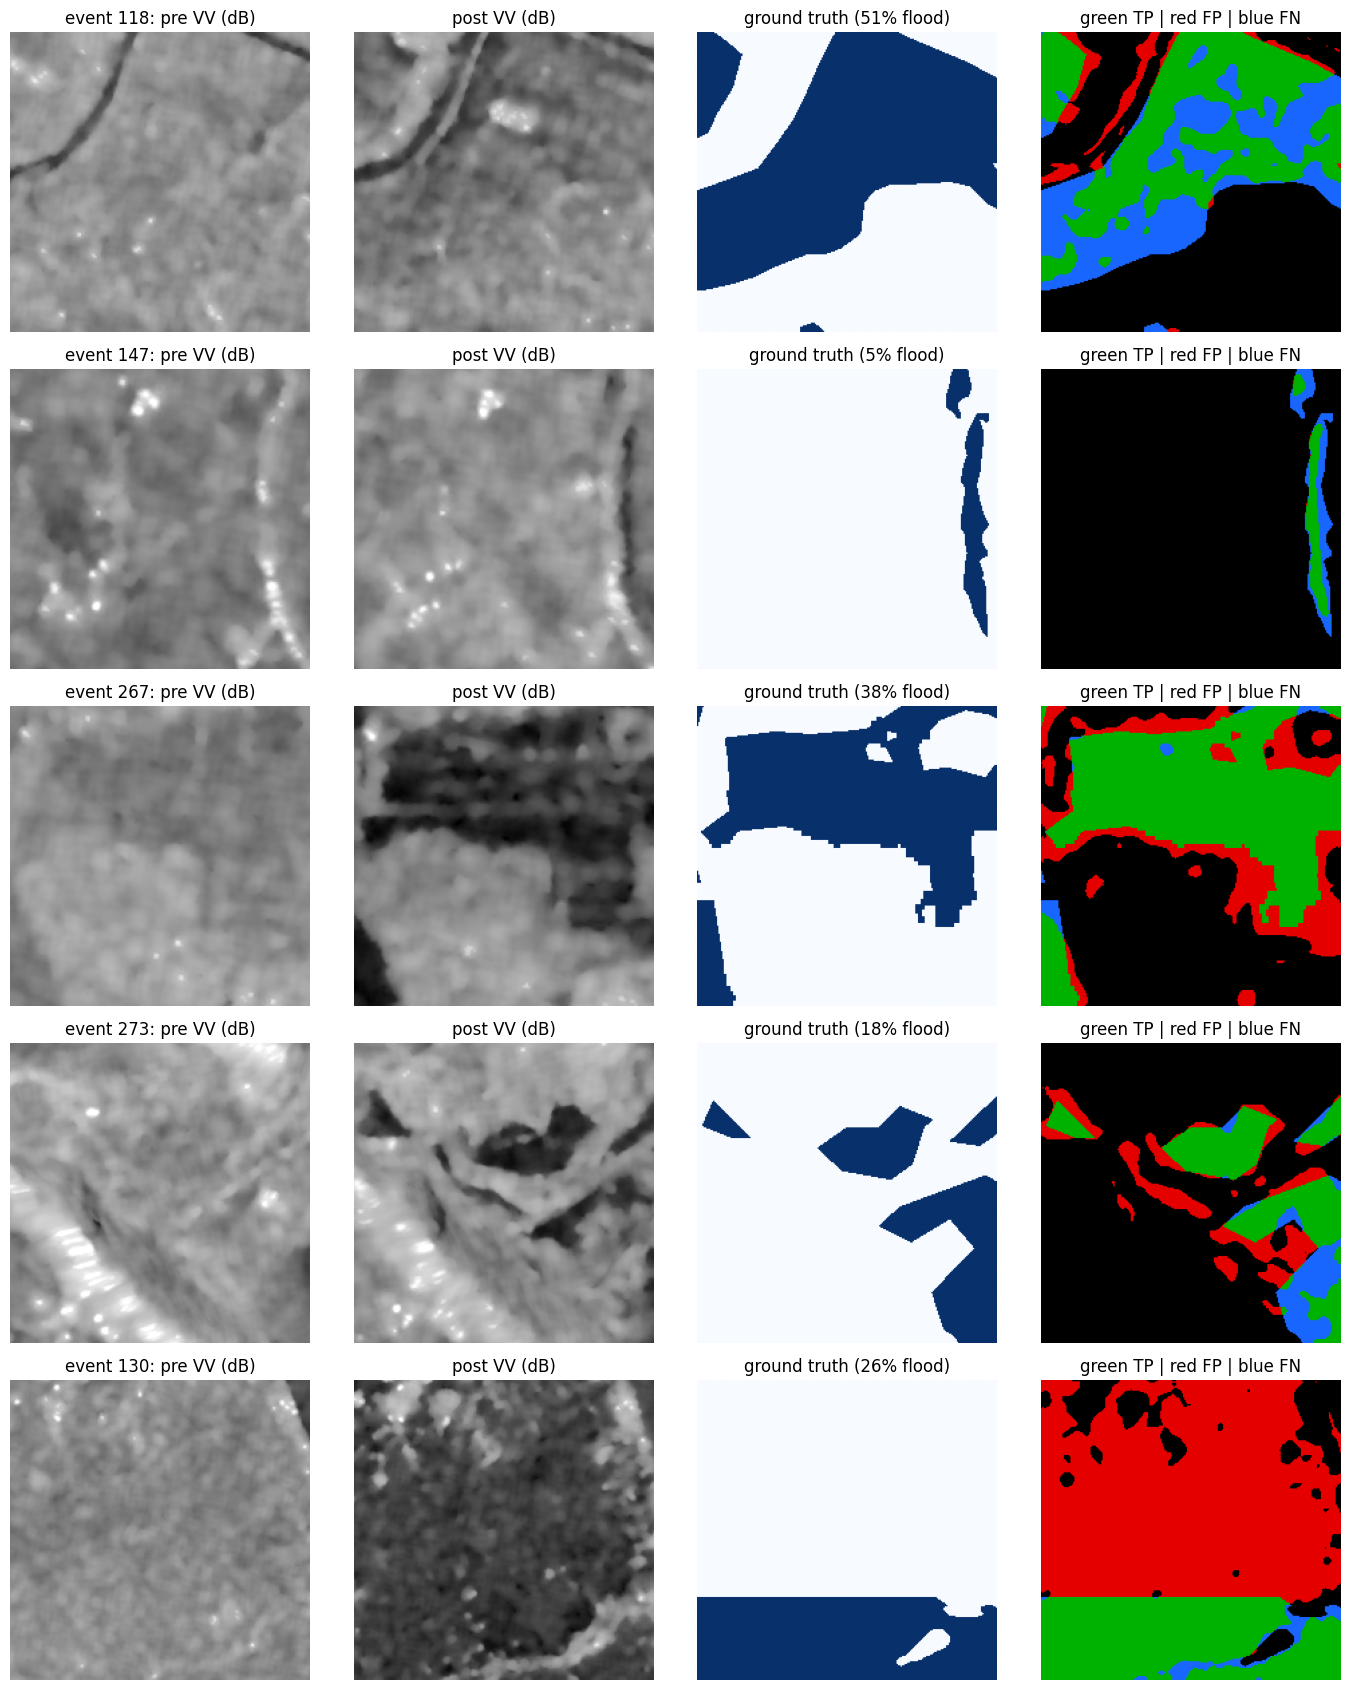

In [76]:
import matplotlib.pyplot as plt

@torch.no_grad()
def show_predictions(model, split, events, seed=0, lo=5, hi=60):
    """One flood-containing patch per event: first pre-event VV, post-event VV, ground truth, error map."""
    rs = np.random.default_rng(seed)
    ds = FloodDataset(split)
    fig, ax = plt.subplots(len(events), 4, figsize=(14, 3.4 * len(events)), squeeze=False)
    for r, ev in enumerate(events):
        cand = rs.permutation(np.where(ds.actid == ev)[0])
        if len(cand) == 0:
            print(f"event {ev} not found in {split}"); [a.axis("off") for a in ax[r]]; continue
        pick = None
        for i in cand[:80]:
            x, t, v = ds[int(i)]
            f = float((t.bool() & v).sum() / v.sum().clamp(min=1) * 100)
            if lo <= f <= hi: pick = (int(i), x, t, v, f); break
        if pick is None:
            pick = (int(cand[0]),) + tuple(ds[int(cand[0])]) + (float("nan"),)
        i, x, t, v, f = pick
        pred = (torch.sigmoid(model(x[None].to(DEVICE)))[0].cpu() > 0.5)
        tb, vb = t.bool(), v.bool()
        db = x.numpy() * STD + MEAN
        err = np.zeros((224, 224, 3)); err[~vb.numpy()] = 0.35
        err[(pred & tb & vb).numpy()] = (0, 0.7, 0); err[(pred & ~tb & vb).numpy()] = (0.9, 0, 0); err[(~pred & tb & vb).numpy()] = (0.1, 0.4, 1)
        ax[r, 0].imshow(db[0], cmap="gray", vmin=-25, vmax=0); ax[r, 0].set_title(f"event {ev}: pre VV (dB)")
        ax[r, 1].imshow(db[4], cmap="gray", vmin=-25, vmax=0); ax[r, 1].set_title("post VV (dB)")
        ax[r, 2].imshow(np.where(vb, tb, np.nan), cmap="Blues", vmin=0, vmax=1); ax[r, 2].set_title(f"ground truth ({f:.0f}% flood)")
        ax[r, 3].imshow(err); ax[r, 3].set_title("green TP | red FP | blue FN")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.show()

show_predictions(unet, "test_00", events=[118, 147, 267, 273, 130])     # weak events and the best one

## 14. Training recipe, seeds and channel selection
New training function with: a cosine schedule that **ends** at the last epoch, a seed per run, selectable input channels, and results saved per run (`results/<run>.json`) so an interrupted session can resume.
Test data is **not** touched here; only validation is evaluated. Final test numbers come later from the saved checkpoints on a fresh test shard.

In [77]:
def evaluate_model2(model, split, channels):
    with torch.no_grad():
        return evaluate(lambda x: torch.sigmoid(model(x)), make_loader2(split, 16, channels))

def train_model2(model, run, channels, epochs, lr, batch_size=16, patience=5, weight_decay=1e-4):
    model = model.to(DEVICE)
    tr = make_loader2("train", batch_size, channels, augment=True, shuffle=True)
    va = make_loader2("val", batch_size, channels)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    ckpt = ROOT / "checkpoints" / f"{run}.pt"
    best, best_ep, bad, hist = -1.0, 0, 0, []
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, t, v in tr:
            x, t, v = x.to(DEVICE), t.to(DEVICE), v.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                logits = model(x)
            loss = masked_bce_dice(logits.float(), t, v)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * len(x)
        sched.step(); model.eval()
        with torch.no_grad():
            pooled, _ = evaluate(lambda x: torch.sigmoid(model(x)), va)
        hist.append({"epoch": ep, "train_loss": run_loss / len(tr.dataset), **{f"val_{k}": val for k, val in pooled.items()}})
        print(f"[{run}] ep {ep:02d} | loss {hist[-1]['train_loss']:.4f} | val IoU {pooled['IoU']:.4f} | {time.time() - t0:.0f}s")
        if pooled["IoU"] > best:
            best, best_ep, bad = pooled["IoU"], ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    pd.DataFrame(hist).to_csv(ROOT / "logs" / f"{run}_history.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    del tr, va; gc.collect()
    return model.eval(), {"best_val_iou": best, "best_epoch": best_ep, "epochs_run": len(hist)}

def run_experiment(name, channels, seeds, epochs, lr, base=32, model_fn=None):
    """Train one model per seed (skipping finished runs); results saved to results/<name>_s<seed>.json."""
    for s in seeds:
        run = f"{name}_s{s}"
        out = ROOT / "results" / f"{run}.json"
        if out.exists():
            print(run, "already done"); continue
        set_seed(s)
        model = model_fn(len(channels)) if model_fn else UNet(in_ch=len(channels), base=base)
        model, info = train_model2(model, run, list(channels), epochs, lr)
        pooled, per_event = evaluate_model2(model, "val", list(channels))
        out.write_text(json.dumps({"run": run, "channels": list(channels), "epochs": epochs, "lr": lr,
                                   "params": sum(p.numel() for p in model.parameters()),
                                   **info, "val": pooled, "val_per_event": per_event.to_dict("records")}))
        del model; gc.collect(); torch.cuda.empty_cache()

def summarize(prefixes):
    """Mean +/- sd over seeds of validation metrics, one row per experiment name."""
    rows = []
    for p in prefixes:
        rs = [json.loads(f.read_text()) for f in sorted((ROOT / "results").glob(f"{p}_s*.json"))]
        if not rs:
            continue
        row = {"experiment": p, "seeds": len(rs), "params_M": round(rs[0]["params"] / 1e6, 2),
               "best_epoch": ", ".join(str(r["best_epoch"]) for r in rs)}
        for k in ["IoU", "F1", "precision", "recall"]:
            a = np.array([r["val"][k] for r in rs])
            row[k] = f"{a.mean():.3f} +/- {a.std(ddof=1) if len(a) > 1 else 0:.3f}"
        rows.append(row)
    return pd.DataFrame(rows).set_index("experiment")

### 14a. Compare two training recipes (6 channels, one seed each, about 15 min per run)
Recipe A: learning rate 1e-3, 10 epochs. Recipe B: learning rate 3e-4, 12 epochs. The recipe with the higher **validation** IoU (and smoother curve) is used for everything that follows.

In [78]:
ALL_CH = list(range(6))
RECIPES = {"A": dict(lr=1e-3, epochs=10), "B": dict(lr=3e-4, epochs=12)}

for k, r in RECIPES.items():
    run_experiment(f"recipe{k}_6ch", ALL_CH, seeds=(0,), **r)

display(summarize([f"recipe{k}_6ch" for k in RECIPES]))
for k in RECIPES:
    display(pd.read_csv(ROOT / "logs" / f"recipe{k}_6ch_s0_history.csv").round(4))

[recipeA_6ch_s0] ep 01 | loss 0.5405 | val IoU 0.6614 | 81s
[recipeA_6ch_s0] ep 02 | loss 0.4044 | val IoU 0.6723 | 81s
[recipeA_6ch_s0] ep 03 | loss 0.3778 | val IoU 0.6569 | 81s
[recipeA_6ch_s0] ep 04 | loss 0.3517 | val IoU 0.6688 | 81s
[recipeA_6ch_s0] ep 05 | loss 0.3356 | val IoU 0.6640 | 81s
[recipeA_6ch_s0] ep 06 | loss 0.3276 | val IoU 0.6636 | 81s
[recipeA_6ch_s0] ep 07 | loss 0.3159 | val IoU 0.6637 | 81s
early stopping
[recipeB_6ch_s0] ep 01 | loss 0.7049 | val IoU 0.6522 | 81s
[recipeB_6ch_s0] ep 02 | loss 0.4529 | val IoU 0.6733 | 81s
[recipeB_6ch_s0] ep 03 | loss 0.3845 | val IoU 0.6267 | 81s
[recipeB_6ch_s0] ep 04 | loss 0.3524 | val IoU 0.6603 | 81s
[recipeB_6ch_s0] ep 05 | loss 0.3331 | val IoU 0.6373 | 81s
[recipeB_6ch_s0] ep 06 | loss 0.3192 | val IoU 0.6737 | 81s
[recipeB_6ch_s0] ep 07 | loss 0.3041 | val IoU 0.6708 | 81s
[recipeB_6ch_s0] ep 08 | loss 0.2938 | val IoU 0.6209 | 81s
[recipeB_6ch_s0] ep 09 | loss 0.2771 | val IoU 0.6250 | 81s
[recipeB_6ch_s0] ep 10 | 

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
recipeA_6ch,1,7.76,2,0.672 +/- 0.000,0.804 +/- 0.000,0.834 +/- 0.000,0.777 +/- 0.000
recipeB_6ch,1,7.76,6,0.674 +/- 0.000,0.805 +/- 0.000,0.802 +/- 0.000,0.808 +/- 0.000


,epoch,train_loss,val_IoU,val_F1,val_precision,val_recall
0,1,0.5405,0.6614,0.7962,0.8026,0.7899
1,2,0.4044,0.6723,0.8040,0.8336,0.7765
2,3,0.3778,0.6569,0.7929,0.8487,0.7440
3,4,0.3517,0.6688,0.8015,0.8147,0.7888
4,5,0.3356,0.6640,0.7981,0.7916,0.8047
5,6,0.3276,0.6636,0.7978,0.7823,0.8139
6,7,0.3159,0.6637,0.7979,0.8260,0.7716


,epoch,train_loss,val_IoU,val_F1,val_precision,val_recall
0,1,0.7049,0.6522,0.7895,0.7488,0.8348
1,2,0.4529,0.6733,0.8047,0.8274,0.7833
2,3,0.3845,0.6267,0.7705,0.7699,0.7711
3,4,0.3524,0.6603,0.7954,0.7772,0.8145
4,5,0.3331,0.6373,0.7784,0.7246,0.8409
5,6,0.3192,0.6737,0.8050,0.8019,0.8082
6,7,0.3041,0.6708,0.8030,0.8310,0.7767
7,8,0.2938,0.6209,0.7661,0.7169,0.8226
8,9,0.2771,0.6250,0.7692,0.7407,0.8001
9,10,0.2708,0.6427,0.7825,0.7591,0.8073


In [79]:
res = summarize([f"recipe{k}_6ch" for k in RECIPES])
best_key = max(RECIPES, key=lambda k: json.loads((ROOT / "results" / f"recipe{k}_6ch_s0.json").read_text())["best_val_iou"])
RECIPE = RECIPES[best_key]          # <- override by hand if the curves tell a different story
print("Recipe used from now on:", best_key, RECIPE)

Recipe used from now on: B {'lr': 0.0003, 'epochs': 12}


## 15. Channel ablation: does pre-event information help?
Same U-Net and recipe, three input sets, 3 seeds each (9 runs, roughly 2-2.5 hours in total; finished runs are skipped, so the cell can be re-run after an interruption).
- `post2`: post-event VV, VH only.
- `pre1_post4`: the pre-event image closer in time to the flood, plus post-event.
- `all6`: both pre-event images plus post-event.

In [80]:
m = pd.read_csv(PROC / "manifest_trainval.csv")
d = lambda c: pd.to_datetime(m[c], errors="coerce", utc=True)
g1, g2 = (d("post_date") - d("sl1_date")).dt.days.median(), (d("post_date") - d("sl2_date")).dt.days.median()
closer = [2, 3] if (pd.notna(g2) and g2 < g1) else [0, 1]
print(f"median days pre->post: SL1 {g1}, SL2 {g2} -> closer pre-event image = {'sec2' if closer == [2, 3] else 'sec1'}")

CONFIGS = {"post2": [4, 5], "pre1_post4": closer + [4, 5], "all6": ALL_CH}
for name, ch in CONFIGS.items():
    run_experiment(f"abl_{name}", ch, seeds=(0, 1, 2), **RECIPE)

ablation = summarize([f"abl_{n}" for n in CONFIGS])
display(ablation)
ablation.to_csv(ROOT / "results" / "ablation_channels_val.csv")

median days pre->post: SL1 36.0, SL2 60.0 -> closer pre-event image = sec1
[abl_post2_s0] ep 01 | loss 0.9031 | val IoU 0.5206 | 80s
[abl_post2_s0] ep 02 | loss 0.6320 | val IoU 0.5044 | 80s
[abl_post2_s0] ep 03 | loss 0.5601 | val IoU 0.5089 | 80s
[abl_post2_s0] ep 04 | loss 0.5294 | val IoU 0.5125 | 80s
[abl_post2_s0] ep 05 | loss 0.5203 | val IoU 0.5180 | 80s
[abl_post2_s0] ep 06 | loss 0.5019 | val IoU 0.5294 | 80s
[abl_post2_s0] ep 07 | loss 0.4933 | val IoU 0.5191 | 80s
[abl_post2_s0] ep 08 | loss 0.4858 | val IoU 0.5175 | 80s
[abl_post2_s0] ep 09 | loss 0.4811 | val IoU 0.5203 | 80s
[abl_post2_s0] ep 10 | loss 0.4722 | val IoU 0.5179 | 80s
[abl_post2_s0] ep 11 | loss 0.4701 | val IoU 0.5219 | 80s
early stopping
[abl_post2_s1] ep 01 | loss 0.8304 | val IoU 0.5096 | 80s
[abl_post2_s1] ep 02 | loss 0.6083 | val IoU 0.5126 | 80s
[abl_post2_s1] ep 03 | loss 0.5517 | val IoU 0.5162 | 80s
[abl_post2_s1] ep 04 | loss 0.5247 | val IoU 0.5080 | 80s
[abl_post2_s1] ep 05 | loss 0.5136 | val

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_post2,3,7.76,"6, 9, 12",0.532 +/- 0.003,0.695 +/- 0.002,0.639 +/- 0.013,0.762 +/- 0.014
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
abl_all6,3,7.76,"6, 1, 8",0.668 +/- 0.005,0.801 +/- 0.003,0.793 +/- 0.015,0.810 +/- 0.013


In [81]:
# ============================================================
# NEXT: (1) test-vs-train distribution check
#       (2) Multi-Temporal U-Nets: "mt_diff" (no attention) and "mt_attn" (temporal attention + attention gates)
#       (3) train both with the fixed recipe, 3 seeds, and compare with the earlier ablation (validation only)
# ============================================================
import math

# ---------------------------------------------------------------- 1. distribution check
def _gap(m):
    d = lambda c: pd.to_datetime(m[c], errors="coerce", utc=True)
    return (d("post_date") - d("sl1_date")).dt.days

_man = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
_test = pd.read_csv(PROC / "manifest_test_00.csv", dtype={"sample_id": str, "shard": str})
_parts = {"train": _man[_man.split == "train"], "val": _man[_man.split == "val"], "test": _test}

rows = []
for k, mm in _parts.items():
    g = _gap(mm)
    rows.append({"split": k, "patches": len(mm), "events": mm.actid.nunique(),
                 "no_flood_%": round((mm.pflood == 0).mean() * 100, 1), "mean_flood_%": round(mm.pflood.mean(), 1),
                 "gap_median_d": g.median(), "gap_p10": g.quantile(.1), "gap_p90": g.quantile(.9),
                 "gap>60d_%": round((g > 60).mean() * 100, 1)})
print("Train vs validation vs test (gap = days from first pre-event image to post-event image):")
display(pd.DataFrame(rows).set_index("split"))

ev = pd.concat([mm.assign(split=k) for k, mm in _parts.items() if k != "train"])
ev["gap"] = _gap(ev)
display(ev.groupby(["split", "actid"]).agg(patches=("pflood", "size"), gap_median=("gap", "median"),
                                           no_flood_pct=("pflood", lambda x: round((x == 0).mean() * 100, 1))))

if all(k in globals() for k in ("val_df", "test_df", "group_metrics")):
    for name, d in [("VALIDATION", val_df), ("TEST", test_df)]:
        empty = d["flood_frac_%"] == 0
        full = metrics_from_counts(d.tp.sum(), d.fp.sum(), d.fn.sum(), 0)["IoU"]
        no_fp = metrics_from_counts(d.tp.sum(), d.fp[~empty].sum(), d.fn.sum(), 0)["IoU"]
        print(f"{name}: IoU {full:.3f} | IoU if empty patches had zero false positives {no_fp:.3f} | "
              f"empty patches give {d.fp[empty].sum() / max(d.fp.sum(), 1) * 100:.0f}% of all false-positive pixels")
    t = test_df.copy(); t["gap_bin"] = pd.cut(t.gap_days, [60, 90, 180, 365, 100000])
    print("TEST: U-Net (6 channels) IoU by pre->post gap:"); display(group_metrics(t, "gap_bin").round(3))

# ---------------------------------------------------------------- 2. models
class AttentionGate(nn.Module):
    """Additive attention gate on a skip connection (Oktay et al., Attention U-Net)."""
    def __init__(self, g_ch, x_ch, inter):
        super().__init__()
        self.wg  = nn.Sequential(nn.Conv2d(g_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.wx  = nn.Sequential(nn.Conv2d(x_ch, inter, 1, bias=False), nn.BatchNorm2d(inter))
        self.psi = nn.Sequential(nn.Conv2d(inter, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
    def forward(self, g, x):                                   # g: upsampled decoder features, x: skip features
        return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class TemporalFusion(nn.Module):
    """Fuse per-timestep features f (B,3,C,H,W; order pre1, pre2, post) into one map.
       attention=False: reference = mean of the two pre-event features.
       attention=True : reference = per-pixel softmax-weighted mix of the pre-event features, the weights
                        coming from similarity to the post-event features (the model chooses which pre-event image to trust)."""
    def __init__(self, c, attention):
        super().__init__()
        self.attention = attention
        if attention:
            self.q = nn.Conv2d(c, max(c // 2, 8), 1); self.k = nn.Conv2d(c, max(c // 2, 8), 1)
        self.mix = nn.Sequential(nn.Conv2d(3 * c, c, 1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True))
    def forward(self, f):
        pre, post = f[:, :2], f[:, 2]
        if self.attention:
            q = self.q(post)
            k = torch.stack([self.k(pre[:, i]) for i in range(2)], 1)
            w = torch.softmax((k * q[:, None]).sum(2, keepdim=True) / math.sqrt(q.shape[1]), dim=1)
            ref = (w * pre).sum(1)
        else:
            ref = pre.mean(1)
        return self.mix(torch.cat([post, post - ref, ref], 1))      # post, change, reference

class MTUNet(nn.Module):
    """Multi-temporal U-Net: ONE encoder shared by the 3 timesteps (2 channels each), temporal fusion at every scale,
       U-Net decoder (with attention gates on the skips if attention=True). Input: (B,6,H,W) in the usual channel order."""
    def __init__(self, base=32, attention=True):
        super().__init__()
        self.attention = attention
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc  = nn.ModuleList([DoubleConv(2, c[0])] + [DoubleConv(c[i], c[i + 1]) for i in range(4)])
        self.fuse = nn.ModuleList([TemporalFusion(ch, attention) for ch in c])
        self.up   = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, stride=2) for i in range(4)])
        self.gate = nn.ModuleList([AttentionGate(c[i], c[i], max(c[i] // 2, 8)) for i in range(4)]) if attention else None
        self.dec  = nn.ModuleList([DoubleConv(c[i] * 2, c[i]) for i in range(4)])
        self.head = nn.Conv2d(c[0], 1, 1)

    def forward(self, x):
        B, _, H, W = x.shape
        h = x.reshape(B, 3, 2, H, W).reshape(B * 3, 2, H, W)         # (pre1, pre2, post) x (VV, VH)
        feats = []
        for i, e in enumerate(self.enc):
            h = e(h if i == 0 else F.max_pool2d(h, 2))
            feats.append(self.fuse[i](h.reshape(B, 3, *h.shape[1:])))
        x = feats.pop()
        for i in reversed(range(4)):
            u, s = self.up[i](x), feats.pop()
            if self.attention:
                s = self.gate[i](u, s)
            x = self.dec[i](torch.cat([u, s], 1))
        return self.head(x).squeeze(1)

MT_BASE = 30                          # ~7.8 M parameters for mt_diff, i.e. the same size as the plain U-Net
for att in (False, True):
    print(f"MTUNet(attention={att}, base={MT_BASE}) parameters: {sum(p.numel() for p in MTUNet(MT_BASE, att).parameters()) / 1e6:.2f} M "
          f"(plain U-Net: 7.76 M)")

# ---------------------------------------------------------------- 3. train (fixed recipe, validation only; resumable)
RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))
ALL_CH = globals().get("ALL_CH", list(range(6)))
SEEDS = (0, 1, 2)                       # use (0,) for a first quick look; finished runs are skipped on re-run

for name, att in [("mt_diff", False), ("mt_attn", True)]:
    run_experiment(name, ALL_CH, seeds=SEEDS, model_fn=lambda n, a=att: MTUNet(MT_BASE, a), **RECIPE)

NAMES = ["abl_post2", "abl_pre1_post4", "abl_all6", "mt_diff", "mt_attn"]
table = summarize(NAMES)
display(table)
table.to_csv(ROOT / "results" / "model_comparison_val.csv")

def per_event_table(prefixes):
    out = {}
    for p in prefixes:
        rs = [json.loads(f.read_text()) for f in sorted((ROOT / "results").glob(f"{p}_s*.json"))]
        out[p] = pd.DataFrame([{r_["actid"]: r_["IoU"] for r_ in r["val_per_event"]} for r in rs]).mean()
    return pd.DataFrame(out).round(3)
print("Validation IoU per event (mean over seeds):")
display(per_event_table(NAMES))

Train vs validation vs test (gap = days from first pre-event image to post-event image):


,patches,events,no_flood_%,mean_flood_%,gap_median_d,gap_p10,gap_p90,gap>60d_%
split,,,,,,,,
train,7925,22,14.2,15.2,24.0,12.0,108.0,32.3
val,3684,3,27.3,10.8,48.0,12.0,102.0,18.6
test,6000,9,69.0,6.3,168.0,144.0,228.0,100.0


patches  gap_median  no_flood_pct
split actid                                     
test  118          342        96.0          71.9
      130          373       144.0          35.1
      147         1958       168.0          88.3
      174          120       360.0          90.8
      205          130       126.0          48.5
      267          504       156.0          62.7
      273          256       203.0          74.2
      275         1356       228.0          49.3
      277          961       210.0          71.5
val   555          684       102.0          33.9
      1111007     1500        48.0          35.1
      1111011     1500        12.0          16.5

VALIDATION: IoU 0.674 | IoU if empty patches had zero false positives 0.677 | empty patches give 3% of all false-positive pixels
TEST: IoU 0.661 | IoU if empty patches had zero false positives 0.747 | empty patches give 47% of all false-positive pixels
TEST: U-Net (6 channels) IoU by pre->post gap:


,patches,IoU,F1,precision,recall
gap_bin,,,,,
"(60, 90]",168,0.425,0.597,0.821,0.469
"(90, 180]",3139,0.641,0.781,0.695,0.892
"(180, 365]",2693,0.715,0.834,0.792,0.880


MTUNet(attention=False, base=30) parameters: 7.75 M (plain U-Net: 7.76 M)
MTUNet(attention=True, base=30) parameters: 8.13 M (plain U-Net: 7.76 M)
[mt_diff_s0] ep 01 | loss 0.6999 | val IoU 0.6451 | 168s
[mt_diff_s0] ep 02 | loss 0.4368 | val IoU 0.6684 | 167s
[mt_diff_s0] ep 03 | loss 0.3653 | val IoU 0.6524 | 167s
[mt_diff_s0] ep 04 | loss 0.3352 | val IoU 0.6446 | 168s
[mt_diff_s0] ep 05 | loss 0.3131 | val IoU 0.6448 | 167s
[mt_diff_s0] ep 06 | loss 0.2951 | val IoU 0.6245 | 167s
[mt_diff_s0] ep 07 | loss 0.2858 | val IoU 0.6466 | 167s
early stopping
[mt_diff_s1] ep 01 | loss 0.6578 | val IoU 0.6737 | 168s
[mt_diff_s1] ep 02 | loss 0.4156 | val IoU 0.6369 | 167s
[mt_diff_s1] ep 03 | loss 0.3503 | val IoU 0.6669 | 167s
[mt_diff_s1] ep 04 | loss 0.3245 | val IoU 0.6471 | 168s
[mt_diff_s1] ep 05 | loss 0.3073 | val IoU 0.6582 | 167s
[mt_diff_s1] ep 06 | loss 0.2910 | val IoU 0.6504 | 167s
early stopping
[mt_diff_s2] ep 01 | loss 0.7417 | val IoU 0.5656 | 168s
[mt_diff_s2] ep 02 | loss

,seeds,params_M,best_epoch,IoU,F1,precision,recall
experiment,,,,,,,
abl_post2,3,7.76,"6, 9, 12",0.532 +/- 0.003,0.695 +/- 0.002,0.639 +/- 0.013,0.762 +/- 0.014
abl_pre1_post4,3,7.76,"8, 3, 5",0.684 +/- 0.008,0.812 +/- 0.006,0.816 +/- 0.009,0.809 +/- 0.002
abl_all6,3,7.76,"6, 1, 8",0.668 +/- 0.005,0.801 +/- 0.003,0.793 +/- 0.015,0.810 +/- 0.013
mt_diff,3,7.75,"2, 1, 2",0.666 +/- 0.010,0.799 +/- 0.007,0.793 +/- 0.018,0.806 +/- 0.017
mt_attn,3,8.13,"1, 1, 6",0.665 +/- 0.001,0.798 +/- 0.001,0.784 +/- 0.022,0.814 +/- 0.023


Validation IoU per event (mean over seeds):


,abl_post2,abl_pre1_post4,abl_all6,mt_diff,mt_attn
555,0.372,0.532,0.516,0.503,0.506
1111007,0.481,0.632,0.625,0.615,0.624
1111011,0.606,0.750,0.723,0.726,0.717


In [82]:
# ============================================================
# NEXT: fix the "too many false alarms on flood-free patches" problem (test set: 69% empty patches, training: 14%)
#   1. add extra flood-free TRAINING patches (hard ones first: patches that contain permanent water)
#   2. retrain the chosen configuration with them (3 seeds)
#   3. evaluate on validation three ways: as is, and re-weighted so that flood-free patches are 50% / 69% of patches,
#      plus a "minimum predicted flood area" rule (patches with fewer predicted flood pixels are set to no-flood)
# Validation only. Nothing here is tuned on test. (The 69% is a rough prior taken from the test set's metadata; say so in the report.)
# ============================================================

# ---------------------------------------------------------------- settings
MODEL_NAME = "pre1_post4"                                     # best conventional configuration so far (val IoU 0.684)
CHANNELS   = globals().get("closer", [0, 1]) + [4, 5]         # closer pre-event image + post-event image
MODEL_FN   = lambda n: UNet(in_ch=n, base=32)
# To use a multi-temporal model instead (once you have seen its table), e.g.:
#   MODEL_NAME, CHANNELS, MODEL_FN = "mt_attn", list(range(6)), (lambda n: MTUNet(30, True))
SEEDS = (0, 1, 2)
EXTRA_PER_EVENT_CAP = 1000
BASE_RUN = {"pre1_post4": "abl_pre1_post4", "all6": "abl_all6", "post2": "abl_post2"}.get(MODEL_NAME, MODEL_NAME)
RECIPE = globals().get("RECIPE", dict(lr=3e-4, epochs=12))

# ---------------------------------------------------------------- 1. extra flood-free training patches
EXTRA_MANIFEST = PROC / "manifest_train_extra.csv"
if EXTRA_MANIFEST.exists():
    extra = pd.read_csv(EXTRA_MANIFEST, dtype={"sample_id": str, "shard": str})
else:
    cur = pd.read_csv(PROC / "manifest_trainval.csv", dtype={"sample_id": str, "shard": str})
    allm = pd.read_csv(DATA / "train_metadata_v2.csv", dtype={"sample_id": str, "shard": str})
    val_events = set(cur[cur.split == "val"].actid)
    used = set(zip(cur.shard, cur.sample_id))
    allm["used"] = [k in used for k in zip(allm.shard, allm.sample_id)]
    cand = allm[~allm.actid.isin(val_events) & (allm.pflood == 0) & ~allm.used]
    rng = np.random.default_rng(SEED)
    picks = []
    for ev, g in cand.groupby("actid"):
        g = g.assign(hard=g.pwater > 0, r=rng.random(len(g))).sort_values(["hard", "r"], ascending=[False, True])
        picks.append(g.head(EXTRA_PER_EVENT_CAP))
    extra = pd.concat(picks).sort_values(["shard", "sample_id"]).reset_index(drop=True)
    extra["split"] = "train_extra"; extra["row"] = np.arange(len(extra))
    extra.to_csv(EXTRA_MANIFEST, index=False)

cur = pd.read_csv(PROC / "manifest_trainval.csv")
n_tr = int((cur.split == "train").sum()); n_tr_empty = int(((cur.split == "train") & (cur.pflood == 0)).sum())
print(f"Extra flood-free patches: {len(extra)} from {extra.actid.nunique()} events "
      f"({int((extra.pwater > 0).sum())} contain permanent water)")
print(f"Training flood-free share: {n_tr_empty / n_tr * 100:.1f}% -> {(n_tr_empty + len(extra)) / (n_tr + len(extra)) * 100:.1f}% "
      f"(test set: 69%)")
display(extra.groupby("actid").size().rename("extra_patches").to_frame().T)

Xe, Ye = open_arrays("train_extra", len(extra))
for i in sorted(extra.shard.astype(int).unique()):
    key = f"extra_{i:05d}"
    if key in done:
        print(key, "already done"); continue
    sub = extra[extra.shard == f"{i:05d}"]
    p = download_shard("train_GRD", i)
    preprocess_shard(p, {r.sample_id: ("train_extra", r.row) for r in sub.itertuples()}, {"train_extra": Xe}, {"train_extra": Ye})
    p.unlink(); gc.collect(); mark_done(key)
    print(f"{key}: wrote {len(sub)} patches")

# ---------------------------------------------------------------- 2. retrain with the extra patches
from torch.utils.data import ConcatDataset
USE_EXTRA_TRAIN = False

def make_loader2(split, batch_size=16, channels=range(6), augment=False, shuffle=False, workers=2):
    if split == "train" and USE_EXTRA_TRAIN:                 # training = original train + extra flood-free patches
        ds = ConcatDataset([FloodDatasetCh("train", channels, augment=augment),
                            FloodDatasetCh("train_extra", channels, augment=augment)])
    else:
        ds = FloodDatasetCh(split, channels, augment=augment)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=workers > 0)

USE_EXTRA_TRAIN = True
run_experiment(f"extra_{MODEL_NAME}", CHANNELS, seeds=SEEDS, model_fn=MODEL_FN, **RECIPE)
USE_EXTRA_TRAIN = False

# ---------------------------------------------------------------- 3. evaluation on re-weighted validation + minimum-area rule
def load_model(run):
    m = MODEL_FN(len(CHANNELS))
    m.load_state_dict(torch.load(ROOT / "checkpoints" / f"{run}.pt", map_location=DEVICE))
    return m.to(DEVICE).eval()

def weighted_metrics(d, empty_share):
    """Pooled metrics where flood-free patches carry the weight needed to make up `empty_share` of all patches."""
    empty = d["flood_frac_%"] == 0
    w = (empty_share / (1 - empty_share)) * (~empty).sum() / max(empty.sum(), 1)
    return metrics_from_counts(d.tp.sum(), d.fp[~empty].sum() + w * d.fp[empty].sum(), d.fn.sum(), 0)

def with_min_area(d, area):
    """Patches with fewer than `area` predicted flood pixels are set to 'no flood'."""
    d = d.copy()
    drop = (d.tp + d.fp) < area
    d.loc[drop, "fn"] = d.loc[drop, "fn"] + d.loc[drop, "tp"]
    d.loc[drop, ["tp", "fp"]] = 0
    return d

AREAS = [0, 100, 250, 500, 1000, 2500, 5000]

def eval_group(prefix):
    rows = []
    for s in SEEDS:
        run = f"{prefix}_s{s}"
        if not (ROOT / "checkpoints" / f"{run}.pt").exists():
            continue
        d, _, _ = predict_stats(load_model(run), "val", CHANNELS)
        for a in AREAS:
            dd = with_min_area(d, a)
            rows.append({"run": prefix, "seed": s, "min_area_px": a,
                         "IoU_val": metrics_from_counts(dd.tp.sum(), dd.fp.sum(), dd.fn.sum(), 0)["IoU"],
                         "IoU_empty50": weighted_metrics(dd, 0.50)["IoU"], "IoU_empty69": weighted_metrics(dd, 0.69)["IoU"]})
    return pd.DataFrame(rows)

res = pd.concat([eval_group(BASE_RUN), eval_group(f"extra_{MODEL_NAME}")], ignore_index=True)
res.to_csv(ROOT / "results" / f"extra_empty_{MODEL_NAME}_val.csv", index=False)

print("No post-processing (min area 0): mean +/- sd over seeds")
a0 = res[res.min_area_px == 0].groupby("run")[["IoU_val", "IoU_empty50", "IoU_empty69"]].agg(["mean", "std"]).round(4)
display(a0)
print("Mean validation IoU by minimum predicted flood area (pixels):")
display(res.groupby(["min_area_px", "run"])[["IoU_val", "IoU_empty50", "IoU_empty69"]].mean().round(4).unstack("run"))

Extra flood-free patches: 1160 from 3 events (1160 contain permanent water)
Training flood-free share: 14.2% -> 25.2% (test set: 69%)


actid,1111004,1111009,1111013
extra_patches,35,125,1000


train_GRD/shard-00000.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00000.tar: downloading bytes:           |  0.00B            

extra_00000: wrote 26 patches


train_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

... (10 outputs left out)

extra_00004: wrote 276 patches
[extra_pre1_post4_s0] ep 01 | loss 0.8326 | val IoU 0.6806 | 90s
[extra_pre1_post4_s0] ep 02 | loss 0.4981 | val IoU 0.6663 | 90s
[extra_pre1_post4_s0] ep 03 | loss 0.3988 | val IoU 0.6767 | 90s
[extra_pre1_post4_s0] ep 04 | loss 0.3569 | val IoU 0.6874 | 90s
[extra_pre1_post4_s0] ep 05 | loss 0.3442 | val IoU 0.6410 | 90s
[extra_pre1_post4_s0] ep 06 | loss 0.3321 | val IoU 0.6232 | 90s
[extra_pre1_post4_s0] ep 07 | loss 0.3246 | val IoU 0.6844 | 90s
[extra_pre1_post4_s0] ep 08 | loss 0.3100 | val IoU 0.6757 | 90s
[extra_pre1_post4_s0] ep 09 | loss 0.2990 | val IoU 0.6781 | 90s
early stopping
[extra_pre1_post4_s1] ep 01 | loss 0.8133 | val IoU 0.6806 | 90s
[extra_pre1_post4_s1] ep 02 | loss 0.4739 | val IoU 0.6815 | 90s
[extra_pre1_post4_s1] ep 03 | loss 0.3946 | val IoU 0.6761 | 90s
[extra_pre1_post4_s1] ep 04 | loss 0.3577 | val IoU 0.6639 | 90s
[extra_pre1_post4_s1] ep 05 | loss 0.3412 | val IoU 0.6822 | 90s
[extra_pre1_post4_s1] ep 06 | loss 0.3273 | 

IoU_val         IoU_empty50         IoU_empty69        
                    mean     std        mean     std        mean     std
run                                                                     
abl_pre1_post4    0.6841  0.0080      0.6773  0.0090      0.6644  0.0112
extra_pre1_post4  0.6860  0.0033      0.6796  0.0028      0.6672  0.0020

Mean validation IoU by minimum predicted flood area (pixels):


IoU_val                     IoU_empty50                   \
run         abl_pre1_post4 extra_pre1_post4 abl_pre1_post4 extra_pre1_post4   
min_area_px                                                                   
0                   0.6841           0.6860         0.6773           0.6796   
100                 0.6843           0.6861         0.6779           0.6800   
250                 0.6842           0.6859         0.6783           0.6803   
500                 0.6837           0.6853         0.6786           0.6806   
1000                0.6816           0.6828         0.6776           0.6789   
2500                0.6709           0.6713         0.6681           0.6685   
5000                0.6488           0.6477         0.6474           0.6463   

               IoU_empty69                   
run         abl_pre1_post4 extra_pre1_post4  
min_area_px                                  
0                   0.6644           0.6672  
100                 0.6656           0.6683  
250                 0.6671           0.6696  
500                 0.6689           0.6714  
1000                0.6698           0.6713  
2500                0.6626           0.6632  
5000                0.6447           0.6436

In [83]:
# ============================================================
# FINAL EVALUATION on FRESH test shard(s) (never looked at before).
#   1. download + convert the fresh test shard(s), check that their events are not in train/val
#   2. evaluate every trained configuration (all seeds) once, with the post-processing rule fixed in advance
#   3. report mean +/- sd over seeds, per-event IoU, and differences between configurations
# Rules: no model selection, no tuning and no re-runs based on these numbers. MIN_AREA was chosen on validation.
# ============================================================
FRESH_SHARDS = [1, 2]            # [1] for a quicker look (each shard: ~10 GB download, about 6,000 patches)
MIN_AREA = 500                   # pixels; fixed in advance from the validation sweep
SEEDS = (0, 1, 2)
BASE = globals().get("closer", [0, 1])
ALL_CH = list(range(6))

# ---------------------------------------------------------------- 1. fresh test data
trainval_events = set(pd.read_csv(PROC / "manifest_trainval.csv").actid)
test0_events = set(pd.read_csv(PROC / "manifest_test_00.csv").actid)
EVAL_SPLITS, LEAK = [], set()
for i in FRESH_SHARDS:
    split = f"test_{i:02d}"
    if split not in done:
        p = download_shard("test_GRD", i)
        meta = extract_metadata(p, f"{i:05d}")
        meta["split"] = split; meta["row"] = np.arange(len(meta))
        Xt, Yt = open_arrays(split, len(meta))
        preprocess_shard(p, {r.sample_id: (split, r.row) for r in meta.itertuples()}, {split: Xt}, {split: Yt})
        meta.to_csv(PROC / f"manifest_{split}.csv", index=False)
        p.unlink(); gc.collect(); mark_done(split)
    m = pd.read_csv(PROC / f"manifest_{split}.csv")
    ev = set(m.actid)
    LEAK |= ev & trainval_events
    EVAL_SPLITS.append(split)
    print(f"{split}: {len(m):,} patches, {len(ev)} events {sorted(ev)} | flood-free {(m.pflood == 0).mean() * 100:.0f}% | "
          f"events also in train/val: {sorted(ev & trainval_events) or 'none'} | also in test_00: {sorted(ev & test0_events) or 'none'}")
if LEAK:
    print("WARNING: events also present in train/val are EXCLUDED from the evaluation below:", sorted(LEAK))

# ---------------------------------------------------------------- 2. evaluate all configurations
CONFIGS = {
    "abl_post2":        ([4, 5],       lambda n: UNet(in_ch=n, base=32)),
    "abl_pre1_post4":   (BASE + [4, 5], lambda n: UNet(in_ch=n, base=32)),
    "extra_pre1_post4": (BASE + [4, 5], lambda n: UNet(in_ch=n, base=32)),
    "abl_all6":         (ALL_CH,       lambda n: UNet(in_ch=n, base=32)),
    "mt_diff":          (ALL_CH,       lambda n: MTUNet(30, False)),
    "mt_attn":          (ALL_CH,       lambda n: MTUNet(30, True)),
}

rows, ev_rows = [], []
for name, (ch, fn) in CONFIGS.items():
    for s in SEEDS:
        run = f"{name}_s{s}"
        ck = ROOT / "checkpoints" / f"{run}.pt"
        if not ck.exists():
            print("missing checkpoint:", run); continue
        model = fn(len(ch)); model.load_state_dict(torch.load(ck, map_location=DEVICE)); model = model.to(DEVICE).eval()
        d = pd.concat([predict_stats(model, sp, ch)[0] for sp in EVAL_SPLITS], ignore_index=True)
        d = d[~d.actid.isin(LEAK)]
        empty = d["flood_frac_%"] == 0
        for area in (0, MIN_AREA):
            dd = with_min_area(d, area)
            mt = metrics_from_counts(dd.tp.sum(), dd.fp.sum(), dd.fn.sum(), 0)
            rows.append({"model": name, "seed": s, "min_area": area, **mt,
                         "IoU_if_no_FP_on_empty": metrics_from_counts(dd.tp.sum(), dd.fp[~empty].sum(), dd.fn.sum(), 0)["IoU"]})
        ev_rows.append({"model": name, "seed": s, **group_metrics(with_min_area(d, MIN_AREA), "actid")["IoU"].to_dict()})
        del model; gc.collect(); torch.cuda.empty_cache()
    print(name, "done")

R = pd.DataFrame(rows)
R.to_csv(ROOT / "results" / "fresh_test_all_models.csv", index=False)

# ---------------------------------------------------------------- 3. report
ms = lambda x: f"{x.mean():.3f} +/- {(x.std(ddof=1) if len(x) > 1 else 0):.3f}"
order = [c for c in CONFIGS if c in set(R.model)]
for area in (0, MIN_AREA):
    print(f"\nFRESH TEST, pooled over valid pixels, minimum predicted area = {area} px (mean +/- sd over seeds):")
    t = R[R.min_area == area].groupby("model").agg(seeds=("seed", "size"), IoU=("IoU", ms), F1=("F1", ms),
                                                   precision=("precision", ms), recall=("recall", ms),
                                                   IoU_if_no_FP_on_empty=("IoU_if_no_FP_on_empty", ms)).loc[order]
    display(t)

print(f"\nPer-event IoU (minimum area {MIN_AREA} px, mean over seeds):")
E = pd.DataFrame(ev_rows).drop(columns="seed").groupby("model").mean().loc[order]
display(E.T.round(3))

print(f"\nDifference in mean IoU (minimum area {MIN_AREA} px) relative to abl_pre1_post4; compare with the seed sd above:")
mean_iou = R[R.min_area == MIN_AREA].groupby("model")["IoU"].mean()
display((mean_iou - mean_iou.get("abl_pre1_post4", np.nan)).loc[order].round(3).to_frame("delta_IoU"))

test_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

test_GRD/shard-00001.tar: downloading bytes:           |  0.00B            

test_01: 6,000 patches, 8 events [277, 279, 321, 324, 411, 417, 421, 427] | flood-free 82% | events also in train/val: none | also in test_00: [277]


AssertionError: not enough disk

In [84]:
# Read-only audit: inspect disk usage before fresh test evaluation

import shutil
from pathlib import Path

ROOT = Path("/kaggle/working/flood_mapping_project")
DATA = ROOT / "data"
PROC = DATA / "processed"

print("=" * 75)
print("DISK SPACE")
print("=" * 75)

usage = shutil.disk_usage("/kaggle/working")

print(f"Total disk : {usage.total / 1e9:.2f} GB")
print(f"Used disk  : {usage.used / 1e9:.2f} GB")
print(f"Free disk  : {usage.free / 1e9:.2f} GB")

print("\n" + "=" * 75)
print("PROJECT DIRECTORY SIZES")
print("=" * 75)

def directory_size(path):
    if not path.exists():
        return 0

    total = 0
    for f in path.rglob("*"):
        if f.is_file():
            try:
                total += f.stat().st_size
            except OSError:
                pass
    return total

for folder in [
    DATA / "kuro_siwo",
    PROC,
    ROOT / "checkpoints",
    ROOT / "results",
    ROOT / "logs",
]:
    print(
        f"{folder.name:20s}: "
        f"{directory_size(folder) / 1e9:8.2f} GB"
    )

print("\n" + "=" * 75)
print("PROCESSED NUMPY ARRAYS")
print("=" * 75)

if PROC.exists():
    for f in sorted(PROC.glob("*.npy")):
        print(f"{f.name:35s} {f.stat().st_size / 1e9:8.3f} GB")

print("\n" + "=" * 75)
print("FRESH TEST ARTIFACTS")
print("=" * 75)

for i in [1, 2]:
    split = f"test_{i:02d}"

    for filename in [
        f"X_{split}.npy",
        f"Y_{split}.npy",
        f"manifest_{split}.csv",
    ]:
        f = PROC / filename
        print(
            f"{filename:30s}: "
            f"{f.stat().st_size / 1e9:.3f} GB"
            if f.exists()
            else f"{filename:30s}: NOT FOUND"
        )

print("\nDone marker:")
print((PROC / "done.json").read_text() if (PROC / "done.json").exists() else "Not found")

DISK SPACE
Total disk : 20.96 GB
Used disk  : 9.38 GB
Free disk  : 11.56 GB

PROJECT DIRECTORY SIZES
kuro_siwo           :     0.00 GB
processed           :     8.71 GB
checkpoints         :     0.66 GB
results             :     0.00 GB
logs                :     0.00 GB

PROCESSED NUMPY ARRAYS
X_test_00.npy                          1.806 GB
X_test_01.npy                          1.806 GB
X_train.npy                            2.386 GB
X_train_extra.npy                      0.349 GB
X_val.npy                              1.109 GB
Y_test_00.npy                          0.301 GB
Y_test_01.npy                          0.301 GB
Y_train.npy                            0.398 GB
Y_train_extra.npy                      0.058 GB
Y_val.npy                              0.185 GB

FRESH TEST ARTIFACTS
X_test_01.npy                 : 1.806 GB
Y_test_01.npy                 : 0.301 GB
manifest_test_01.csv          : 0.001 GB
X_test_02.npy                 : NOT FOUND
Y_test_02.npy                 : NOT FO

In [85]:
# Cell 2: Remove only the already-evaluated exploratory test_00 arrays

files_to_remove = [
    PROC / "X_test_00.npy",
    PROC / "Y_test_00.npy",
]

print("Files selected for removal:")

for f in files_to_remove:
    if f.exists():
        print(f"{f.name}: {f.stat().st_size / 1e9:.3f} GB")
    else:
        print(f"{f.name}: already absent")

print("\nThe following files will be preserved:")
for f in [
    PROC / "manifest_test_00.csv",
    PROC / "X_test_01.npy",
    PROC / "Y_test_01.npy",
]:
    print(f"{f.name}: {'EXISTS' if f.exists() else 'NOT FOUND'}")

# Delete only the two exploratory arrays
for f in files_to_remove:
    if f.exists():
        f.unlink()

gc.collect()

usage = shutil.disk_usage("/kaggle/working")

print("\n" + "=" * 60)
print("DISK SPACE AFTER CLEANUP")
print("=" * 60)
print(f"Free disk: {usage.free / 1e9:.2f} GB")

Files selected for removal:
X_test_00.npy: 1.806 GB
Y_test_00.npy: 0.301 GB

The following files will be preserved:
manifest_test_00.csv: EXISTS
X_test_01.npy: EXISTS
Y_test_01.npy: EXISTS

DISK SPACE AFTER CLEANUP
Free disk: 11.56 GB


In [86]:
# Cell 3: Verify deleted files and inspect filesystem usage

import os
import shutil
import subprocess
import gc

gc.collect()

print("=" * 65)
print("CHECK DELETED ARRAYS")
print("=" * 65)

for name in ["X_test_00.npy", "Y_test_00.npy"]:
    path = PROC / name
    print(f"{name}: {'STILL EXISTS' if path.exists() else 'DELETED'}")

print("\n" + "=" * 65)
print("CHECK PROCESSED DIRECTORY")
print("=" * 65)

total_size = sum(
    f.stat().st_size
    for f in PROC.iterdir()
    if f.is_file()
)

print(f"Processed directory size: {total_size / 1e9:.2f} GB")

print("\n" + "=" * 65)
print("FILESYSTEM REPORT")
print("=" * 65)

print(subprocess.run(
    ["df", "-h", "/kaggle/working"],
    capture_output=True,
    text=True
).stdout)

print("=" * 65)
print("OPEN FILE HANDLES")
print("=" * 65)

try:
    import psutil

    process = psutil.Process(os.getpid())
    open_files = process.open_files()

    deleted_handles = [
        f.path for f in open_files
        if "test_00" in f.path
    ]

    print("Open test_00 handles:", deleted_handles)

except Exception as e:
    print("Could not inspect open handles:", e)

CHECK DELETED ARRAYS
X_test_00.npy: DELETED
Y_test_00.npy: DELETED

CHECK PROCESSED DIRECTORY
Processed directory size: 6.60 GB

FILESYSTEM REPORT
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  8.8G   11G  45% /kaggle/working

OPEN FILE HANDLES
Open test_00 handles: []


In [89]:
# Cell 6: Extract test shard 2 metadata directly from Hugging Face

import requests
import tarfile
import json
import time
from pathlib import Path

SHARD_ID = 2
SHARD_NAME = f"{SHARD_ID:05d}"

STREAM_URL = (
    "https://huggingface.co/datasets/"
    "orion-ai-lab/Kuro-Siwo-Webdataset/"
    f"resolve/main/test_GRD/shard-{SHARD_NAME}.tar"
)

def extract_metadata_stream(url, shard):
    rows = []
    start = time.time()

    response = requests.get(
        url,
        stream=True,
        allow_redirects=True,
        timeout=(30, 300)
    )
    response.raise_for_status()

    print("Connected to remote shard.")
    print("Archive size:", round(
        int(response.headers.get("Content-Length", 0)) / 1e9, 2
    ), "GB")

    try:
        with tarfile.open(fileobj=response.raw, mode="r|*") as tar:
            for member in tar:
                if not member.isfile() or not member.name.endswith(".info.json"):
                    continue

                info_file = tar.extractfile(member)
                if info_file is None:
                    continue

                info = json.loads(info_file.read())

                row = {
                    "sample_id": Path(member.name).name.split(".")[0],
                    "shard": shard
                }

                row.update({
                    k: v for k, v in info.items()
                    if isinstance(v, (int, float, str, bool, type(None)))
                })

                sources = info.get("sources", {})
                row["sl1_date"] = sources.get("SL1", {}).get("source_date")
                row["sl2_date"] = sources.get("SL2", {}).get("source_date")
                row["post_date"] = sources.get("MS1", {}).get("source_date")

                rows.append(row)

                if len(rows) % 500 == 0:
                    print(f"Metadata extracted: {len(rows):,} samples")

    finally:
        response.close()

    print(f"\nCompleted in {(time.time() - start) / 60:.1f} minutes.")

    return pd.DataFrame(rows)


df_test02 = extract_metadata_stream(STREAM_URL, SHARD_NAME)

assert len(df_test02) > 0, "No metadata extracted!"
assert df_test02["sample_id"].is_unique, "Duplicate sample IDs detected!"

# Identify event overlap
trainval_events = set(
    pd.read_csv(PROC / "manifest_trainval.csv")["actid"]
)

test0_events = set(
    pd.read_csv(PROC / "manifest_test_00.csv")["actid"]
)

test02_events = set(df_test02["actid"])

overlap_trainval = test02_events & trainval_events
overlap_test0 = test02_events & test0_events

print("\n" + "=" * 70)
print("TEST SHARD 2 METADATA SUMMARY")
print("=" * 70)

print("Samples:", len(df_test02))
print("Events:", len(test02_events))
print("Event IDs:", sorted(test02_events))

print("\nOverlap with training/validation:", sorted(overlap_trainval))
print("Overlap with exploratory test shard 0:", sorted(overlap_test0))

print("\nEvent distribution:")
display(
    df_test02.groupby("actid")
    .agg(
        samples=("sample_id", "count"),
        flood_date=("flood_date", "first"),
        mean_flood=("pflood", "mean"),
        zero_flood_patches=("pflood", lambda x: (x == 0).sum())
    )
    .sort_values("samples", ascending=False)
)

# Save metadata only; do not mark the shard as processed.
manifest_path = PROC / "manifest_test_02.csv"
df_test02.to_csv(manifest_path, index=False)

print("\nMetadata saved:", manifest_path)
print("Processed-array completion marker has NOT been changed.")

Connected to remote shard.
Archive size: 10.91 GB
Metadata extracted: 500 samples
Metadata extracted: 1,000 samples
Metadata extracted: 1,500 samples
Metadata extracted: 2,000 samples
Metadata extracted: 2,500 samples
Metadata extracted: 3,000 samples
Metadata extracted: 3,500 samples
Metadata extracted: 4,000 samples
Metadata extracted: 4,500 samples
Metadata extracted: 5,000 samples
Metadata extracted: 5,500 samples
Metadata extracted: 6,000 samples

Completed in 1.5 minutes.

TEST SHARD 2 METADATA SUMMARY
Samples: 6000
Events: 5
Event IDs: [427, 437, 445, 470, 492]

Overlap with training/validation: [470, 492]
Overlap with exploratory test shard 0: []

Event distribution:


,samples,flood_date,mean_flood,zero_flood_patches
actid,,,,
427,4309,2020-02-18 12:00:00,0.459703,3995
470,821,2020-10-05 18:00:00,10.597027,448
445,361,2020-06-26 08:00:00,1.897597,277
492,340,2021-01-01 12:00:00,5.091091,188
437,169,2020-05-10 22:00:00,0.754763,132



Metadata saved: /kaggle/working/flood_mapping_project/data/processed/manifest_test_02.csv
Processed-array completion marker has NOT been changed.


In [90]:
# Cell 7: Final event-overlap audit for test shard 2

# Load manifests
trainval_manifest = pd.read_csv(PROC / "manifest_trainval.csv")
test01_manifest = pd.read_csv(PROC / "manifest_test_01.csv")

trainval_events = set(trainval_manifest["actid"].dropna().astype(int))
test01_events = set(test01_manifest["actid"].dropna().astype(int))

df_test02["actid"] = df_test02["actid"].astype(int)

test02_events = set(df_test02["actid"])

# Identify overlaps
overlap_trainval = test02_events & trainval_events
overlap_test01 = test02_events & test01_events

# Exclude only events already used in training/validation
df_test02["eligible"] = ~df_test02["actid"].isin(trainval_events)

df_test02["exclusion_reason"] = np.where(
    df_test02["eligible"],
    "Eligible",
    "Overlaps training/validation"
)

df_test02_eligible = df_test02[df_test02["eligible"]].copy()

print("=" * 75)
print("TEST SHARD 2: EVENT OVERLAP AUDIT")
print("=" * 75)

print("Events in shard 2:", sorted(test02_events))
print("Training/validation overlap:", sorted(overlap_trainval))
print("Shard 1 overlap:", sorted(overlap_test01))

print("\nEligible events:", sorted(
    set(df_test02_eligible["actid"])
))

print("Eligible samples:", len(df_test02_eligible))
print("Excluded samples:", len(df_test02) - len(df_test02_eligible))

print("\nEvent-level decision:")
display(
    df_test02.groupby("actid")
    .agg(
        samples=("sample_id", "count"),
        eligible=("eligible", "first"),
        exclusion_reason=("exclusion_reason", "first"),
        mean_flood=("pflood", "mean"),
        zero_flood_patches=("pflood", lambda x: (x == 0).sum())
    )
    .sort_values("samples", ascending=False)
)

# Save the eligible manifest separately
eligible_manifest_path = PROC / "manifest_test_02_eligible.csv"

df_test02_eligible.to_csv(
    eligible_manifest_path,
    index=False
)

print("\nEligible manifest saved:", eligible_manifest_path)

assert len(df_test02_eligible) > 0
assert not (
    set(df_test02_eligible["actid"]) & trainval_events
), "Training/validation event leakage detected!"

TEST SHARD 2: EVENT OVERLAP AUDIT
Events in shard 2: [427, 437, 445, 470, 492]
Training/validation overlap: [470, 492]
Shard 1 overlap: [427]

Eligible events: [427, 437, 445]
Eligible samples: 4839
Excluded samples: 1161

Event-level decision:


,samples,eligible,exclusion_reason,mean_flood,zero_flood_patches
actid,,,,,
427,4309,True,Eligible,0.459703,3995
470,821,False,Overlaps training/validation,10.597027,448
445,361,True,Eligible,1.897597,277
492,340,False,Overlaps training/validation,5.091091,188
437,169,True,Eligible,0.754763,132



Eligible manifest saved: /kaggle/working/flood_mapping_project/data/processed/manifest_test_02_eligible.csv


## Next
1. Read the ablation table: if `all6` > `pre1_post4` > `post2` by more than the seed-to-seed spread, multi-temporal input helps and the attention model has something to improve on.
2. Multi-Temporal Attention U-Net (shared per-timestep encoder, temporal attention fusion, attention gates), trained with `run_experiment(..., model_fn=...)` and the same recipe and seeds.
3. Final numbers: load the saved checkpoints (`checkpoints/<run>.pt`) and evaluate once on a fresh `test_GRD` shard.